# Regularización de un MLP sobreajustado en 20 Newsgroups
### Redes Neuronales

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet, 20 categorías), representado con TF-IDF.

Este trabajo parte de una configuración de MLP que **sobreajusta** el problema (guardada en `overfit_config.json`) y estudia cómo cambian su comportamiento y su generalización al incorporar tres familias de regularización como hiperparámetros:

- **Regularización L1, L2 y L1 + L2** sobre los pesos.
- **Dropout.**
- **Batch Normalization.**

## Objetivos
- Medir el efecto de cada técnica de forma aislada (un hiperparámetro por vez, con varias semillas) sobre el rendimiento, el sobreajuste, el **valor absoluto de los pesos**, los **tiempos de entrenamiento**, el **learning rate** adecuado y el **ruido de las curvas de aprendizaje**.
- Incorporar las técnicas al espacio de búsqueda de Optuna (con pruning) y analizar toda la búsqueda, no solo el mejor trial.
- Comparar, con el mismo protocolo, la red sobreajustada, la red con solo early stopping y la mejor red regularizada.
- Justificar los fenómenos observados con los fundamentos teóricos de cada técnica.

## Estructura
0. Setup · 1. Datos y configuración · 2. Preprocesamiento y vectorización · 3. Modelo · 4. Entrenamiento · 5. Fundamentos · 6. Experimentos controlados · 7. Búsqueda con Optuna · 8. Análisis de la búsqueda · 9. Evaluación final · 10. Conclusiones · 11. Exportación

In [1]:
!pip install -q optuna mlflow

## 0. Setup

El notebook está pensado para ejecutarse con GPU. La celda define las importaciones, las semillas y los directorios de salida:

- `SWEEP_SEEDS`: semillas de los experimentos controlados (media ± desvío entre semillas).
- `FINAL_SEEDS`: semillas de la evaluación final.
- `results_reg/`: tablas y configuraciones. `runs_reg/`: logs de TensorBoard. `mlflow_reg.db`: base de MLflow.

In [2]:
import os
import re
import gc
import copy
import json
import time
import random
import zipfile
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import optuna

warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
SWEEP_SEEDS = [42, 123, 2024]
FINAL_SEEDS = [42, 123, 2024, 7, 99]
RESULTS_DIR = "results_reg"
TB_DIR = "runs_reg"
os.makedirs(RESULTS_DIR, exist_ok=True)


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

mlflow.set_tracking_uri("sqlite:///mlflow_reg.db")
mlflow.set_experiment("regularizacion_20newsgroups")

Usando dispositivo: cuda
GPU: Tesla T4


2026/11/10 05:53:54 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/10 05:53:54 INFO mlflow.store.db.utils: Updating database tables
2026/11/10 05:53:59 INFO mlflow.tracking.fluent: Experiment with name 'regularizacion_20newsgroups' does not exist. Creating a new experiment.


<Experiment: artifact_location='/content/mlruns/1', creation_time=1794290039341, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1794290039341, lifecycle_stage='active', name='regularizacion_20newsgroups', tags={}, trace_location=None, workspace='default'>

In [3]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## 1. Datos y configuración de partida

Se usan las particiones oficiales `train` y `test` de `fetch_20newsgroups`, sin encabezados, firmas ni citas. El test se reserva para la evaluación final y no interviene en ninguna decisión de los experimentos ni de la búsqueda.

La configuración sobreajustada (arquitectura, activación, optimizador, `lr`, `batch_size` y preprocesamiento/vectorización) se lee de `overfit_config.json`. Todos los experimentos usan ese preprocesamiento y esa vectorización, de modo que las diferencias entre variantes se deben únicamente a la regularización, al `lr` y al `batch_size`.

In [4]:
CONFIG_PATH = "overfit_config.json"

newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test = fetch_20newsgroups(subset="test", remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"Train: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

with open(CONFIG_PATH) as f:
    overfit_config = json.load(f)
PRE = overfit_config["preprocessing"]
print("\nConfiguración sobreajustada:")
print(json.dumps(overfit_config, indent=2))

Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']
Train: 11314 documentos | Test: 7532 documentos

Configuración sobreajustada:
{
  "hidden_units": [
    64,
    64,
    64
  ],
  "activation": "relu",
  "optimizer": "adam",
  "lr": 0.001,
  "batch_size": 64,
  "epochs": 20,
  "dropout": 0.0,
  "weight_decay": 0.0,
  "preprocessing": {
    "remove_stopwords": true,
    "normalization": "lemmatize",
    "ngram_range": "1gram",
    "max_features": 20000,
    "min_df": 1
  },
  "train_acc": 0.9721577726218097,
  "val_acc": 0.5930181175430844,
  "n_params": 1289684
}


## 2. Preprocesamiento, vectorización y datos en GPU

- `preprocess_text` tokeniza, pasa a minúsculas, conserva tokens alfabéticos y aplica las opciones de stopwords y normalización de la configuración.
- `vectorize_data` ajusta el vocabulario y los pesos IDF **solo con el conjunto de entrenamiento**. `TfidfVectorizer` ya normaliza cada fila con norma L2, por lo que las entradas tienen escala homogénea, condición necesaria para que una penalización L1/L2 con un único λ sea pareja entre pesos.
- Hay dos particiones: una de **búsqueda** (80 % train / 20 % validación, estratificada y fija) donde se hacen todos los experimentos y la búsqueda, y la partición **final** (train completo contra test).
- Las matrices se convierten a tensores densos que quedan **residentes en GPU**, para que los miles de entrenamientos no paguen copias CPU→GPU.
- Se informa la cantidad de documentos que quedan vacíos tras el preprocesamiento: un documento vacío produce un vector nulo que ningún modelo puede ajustar mejor que con un valor constante.

In [5]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    return " ".join(tokens)


def ngram_tuple(name):
    return (1, 1) if name == "1gram" else (1, 2)


def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer


def to_tensors(X, y):
    return (torch.tensor(X.astype(np.float32).toarray(), dtype=torch.float32, device=device),
            torch.tensor(np.asarray(y), dtype=torch.long, device=device))


train_proc = [preprocess_text(t, PRE["remove_stopwords"], PRE["normalization"]) for t in newsgroups_train.data]
test_proc = [preprocess_text(t, PRE["remove_stopwords"], PRE["normalization"]) for t in newsgroups_test.data]
empty_docs = sum(len(t.strip()) == 0 for t in train_proc)
print(f"Documentos vacíos tras el preprocesamiento (train): {empty_docs} de {len(train_proc)} "
      f"({100 * empty_docs / len(train_proc):.2f} %)")

y_all = np.array(newsgroups_train.target)
y_test = np.array(newsgroups_test.target)
IDX_TR, IDX_VAL = train_test_split(np.arange(len(y_all)), test_size=0.2, random_state=SEED, stratify=y_all)
y_tr, y_val = y_all[IDX_TR], y_all[IDX_VAL]

ngram = ngram_tuple(PRE["ngram_range"])
X_tr, X_val, _ = vectorize_data([train_proc[i] for i in IDX_TR], [train_proc[i] for i in IDX_VAL],
                                ngram, PRE["max_features"], PRE["min_df"])
X_full, X_test, _ = vectorize_data(train_proc, test_proc, ngram, PRE["max_features"], PRE["min_df"])

T_TR = to_tensors(X_tr, y_tr)
T_VAL = to_tensors(X_val, y_val)
T_FULL = to_tensors(X_full, y_all)
T_TEST = to_tensors(X_test, y_test)
print("Búsqueda: train", tuple(T_TR[0].shape), "| validación", tuple(T_VAL[0].shape))
print("Final:    train", tuple(T_FULL[0].shape), "| test", tuple(T_TEST[0].shape))
del X_tr, X_val, X_full, X_test
gc.collect()

Documentos vacíos tras el preprocesamiento (train): 320 de 11314 (2.83 %)
Búsqueda: train (9051, 20000) | validación (2263, 20000)
Final:    train (11314, 20000) | test (7532, 20000)


0

## 3. Modelo: MLP con regularización

`MLP` extiende el perceptrón multicapa con dos opciones:

- `dropout`: tras la activación de cada capa oculta, se apaga una proporción aleatoria de neuronas durante el entrenamiento (y la red se usa completa en evaluación).
- `batch_norm`: tras cada capa lineal oculta y antes de la activación se normaliza cada unidad con la media y el desvío del batch, con parámetros `γ` y `β` aprendibles. Al usarla, la capa lineal no lleva bias (queda redundante).

La regularización L1/L2 no es parte del modelo sino de la función de costo. `regularization_penalty` suma a la cross-entropy:

`J = CE + Σ_capas  g^i · ( λ2 · Σ w² + λ1 · Σ |w| )`

sobre los **pesos de las capas lineales** (no los bias ni los parámetros de BatchNorm). `g` (`layer_growth`) permite penalizar más a las capas cercanas a la salida (`i` crece hacia la salida); con `g = 1` el λ es uniforme. Esta formulación explícita corresponde a la presentada en clase (derivada `2λw` para L2 y `±λ` para L1). No equivale a `weight_decay` de Adam, que aplica el decaimiento dentro de la regla adaptativa.

Se incluyen también las funciones que miden los pesos: valor absoluto medio por capa, fracción de pesos casi nulos y poda por magnitud.

In [6]:
ACTIVATIONS = {
    "relu": lambda: nn.ReLU(),
    "tanh": lambda: nn.Tanh(),
    "leaky_relu": lambda: nn.LeakyReLU(0.01),
    "gelu": lambda: nn.GELU(),
    "elu": lambda: nn.ELU(),
    "silu": lambda: nn.SiLU(),
    "selu": lambda: nn.SELU(),
}


class MLP(nn.Module):
    def __init__(self, input_dim, num_classes, hidden_units=(), activation="relu", dropout=0.0, batch_norm=False):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_units:
            layers.append(nn.Linear(prev, h, bias=not batch_norm))
            if batch_norm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(ACTIVATIONS[activation]())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        self.hidden = nn.Sequential(*layers)
        self.out = nn.Linear(prev, num_classes)

    def forward(self, x):
        return self.out(self.hidden(x))


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def weight_layers(model):
    return [m for m in model.modules() if isinstance(m, nn.Linear)]


def regularization_penalty(model, l1, l2, layer_growth=1.0):
    if l1 == 0.0 and l2 == 0.0:
        return 0.0
    penalty = 0.0
    for i, layer in enumerate(weight_layers(model)):
        scale = layer_growth ** i
        w = layer.weight
        if l2 > 0.0:
            penalty = penalty + scale * l2 * (w ** 2).sum()
        if l1 > 0.0:
            penalty = penalty + scale * l1 * w.abs().sum()
    return penalty


def weight_abs_means(model):
    return [layer.weight.detach().abs().mean().item() for layer in weight_layers(model)]


def weight_sparsity(model, threshold):
    total, small = 0, 0
    for layer in weight_layers(model):
        w = layer.weight.detach()
        total += w.numel()
        small += (w.abs() <= threshold).sum().item()
    return small / total


def prune_by_magnitude(model, threshold):
    with torch.no_grad():
        for layer in weight_layers(model):
            layer.weight[layer.weight.abs() < threshold] = 0.0


_dummy = torch.randn(8, 50)
for bn in [False, True]:
    m = MLP(50, NUM_CLASSES, hidden_units=(16, 16), dropout=0.3, batch_norm=bn)
    assert m(_dummy).shape == (8, NUM_CLASSES)
    print(f"batch_norm={bn}: {count_params(m)} parámetros | capas lineales: {len(weight_layers(m))}")

batch_norm=False: 1428 parámetros | capas lineales: 3
batch_norm=True: 1460 parámetros | capas lineales: 3


## 4. Entrenamiento

`train_model` entrena con Adam y reporta por época: `loss` y accuracy de entrenamiento (con las capas de regularización activas, es decir, con dropout encendido y BatchNorm con estadísticas del batch), `loss` y accuracy de evaluación (red completa), tiempo de la época y **valor absoluto medio de los pesos de cada capa lineal**.

- `train_loss` es solo la cross-entropy; la penalidad L1/L2 se suma únicamente para calcular el gradiente. Así se compara de forma directa con `val_loss`.
- Tiempos: `time.perf_counter()` con sincronización de la GPU, por época (entrenamiento, evaluación y costo de la penalidad incluidos) y total. No se incluye el cálculo de estadísticas de pesos.
- **Convergencia**: época en que `val_acc` queda a menos de `CONV_TOL = 0.005` de su máximo, y tiempo acumulado hasta esa época.
- **Early stopping** (`patience`) y **pruning** de Optuna (`trial.report` en cada época) opcionales.
- **Ruido de las curvas** (`curve_noise`): desvío estándar de la diferencia entre la curva y su media móvil de 3 épocas, descartando las primeras 3 épocas (transitorio inicial). Permite comparar qué tan irregular es una curva entre variantes; es un índice relativo, no una magnitud absoluta.
- Los batches de un solo elemento se omiten en entrenamiento, porque BatchNorm no puede estimar la varianza con una muestra.

In [7]:
EVAL_BATCH = 1024
CONV_TOL = 0.005
SPARSITY_THRESHOLD = 1e-3


class TensorLoader:
    def __init__(self, X, y, batch_size, shuffle):
        self.X, self.y = X, y
        self.batch_size = batch_size
        self.shuffle = shuffle

    def __len__(self):
        return (len(self.y) + self.batch_size - 1) // self.batch_size

    def __iter__(self):
        n = len(self.y)
        if self.shuffle:
            order = torch.randperm(n, device=self.X.device)
        else:
            order = torch.arange(n, device=self.X.device)
        for start in range(0, n, self.batch_size):
            idx = order[start:start + self.batch_size]
            if self.shuffle and len(idx) < 2:
                continue
            yield self.X[idx], self.y[idx]


def build_optimizer(model, lr):
    return optim.Adam(model.parameters(), lr=lr)


def _sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


def convergence_epoch(val_accs, tol=CONV_TOL):
    target = max(val_accs) - tol
    return next(i + 1 for i, a in enumerate(val_accs) if a >= target)


def curve_noise(values, skip=3, window=3):
    v = np.asarray(values, dtype=float)[skip:]
    if len(v) < window + 2:
        return float("nan")
    smooth = np.convolve(v, np.ones(window) / window, mode="same")
    return float(np.std((v - smooth)[1:-1]))


def predict(model, loader):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            preds.append(model(xb).argmax(dim=1).cpu())
            labels.append(yb.cpu())
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()


def train_model(model, train_loader, val_loader, optimizer, epochs, l1=0.0, l2=0.0, layer_growth=1.0,
                writer=None, run_name="model", trial=None, patience=None, verbose=True):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": [], "w_abs": []}
    best_val_acc, best_epoch, epochs_no_improve = -1.0, 0, 0
    pruned = False
    log_to_mlflow = mlflow.active_run() is not None

    for epoch in range(epochs):
        _sync()
        t0 = time.perf_counter()

        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            logits = model(xb)
            ce = criterion(logits, yb)
            loss = ce + regularization_penalty(model, l1, l2, layer_growth)
            loss.backward()
            optimizer.step()
            running_loss += ce.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                logits = model(xb)
                running_loss += criterion(logits, yb).item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        _sync()
        epoch_time = time.perf_counter() - t0
        w_means = weight_abs_means(model)

        history["epoch_time"].append(epoch_time)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["w_abs"].append(w_means)

        if verbose:
            print(f"[{run_name}] Epoch {epoch+1}/{epochs} - train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
                  f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f} - {epoch_time:.2f}s")

        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
            writer.add_scalar("epoch_time_s", epoch_time, epoch)
            writer.add_scalar("mean_abs_w_capa1", w_means[0], epoch)
        if log_to_mlflow:
            mlflow.log_metric("train_loss", train_loss, step=epoch)
            mlflow.log_metric("val_loss", val_loss, step=epoch)
            mlflow.log_metric("train_acc", train_acc, step=epoch)
            mlflow.log_metric("val_acc", val_acc, step=epoch)
            mlflow.log_metric("epoch_time_s", epoch_time, step=epoch)
            mlflow.log_metric("mean_abs_w_capa1", w_means[0], step=epoch)

        if val_acc > best_val_acc:
            best_val_acc, best_epoch, epochs_no_improve = val_acc, epoch + 1, 0
        else:
            epochs_no_improve += 1

        if trial is not None:
            trial.report(val_acc, epoch)
            if trial.should_prune():
                pruned = True
                break

        if patience is not None and epochs_no_improve >= patience:
            break

    history["train_time"] = float(sum(history["epoch_time"]))
    history["epochs_run"] = len(history["train_loss"])
    history["best_val_acc"] = best_val_acc
    history["best_epoch"] = best_epoch
    history["final_train_acc"] = history["train_acc"][-1]
    history["final_val_acc"] = history["val_acc"][-1]
    history["conv_epoch"] = convergence_epoch(history["val_acc"])
    history["conv_time"] = float(sum(history["epoch_time"][:history["conv_epoch"]]))

    if trial is not None:
        for k in ["train_time", "epochs_run", "best_epoch", "best_val_acc", "final_train_acc",
                  "final_val_acc", "conv_epoch", "conv_time"]:
            trial.set_user_attr(k, history[k])
    if pruned:
        raise optuna.TrialPruned()
    return history

## 5. Fundamentos: qué se espera de cada técnica

Antes de mirar resultados se explicitan las predicciones de la teoría, que luego se contrastan con lo observado en la sección 10.

| Elemento | Mecanismo | Qué debería observarse |
|---|---|---|
| **Sobreajuste y pesos** | Para ajustar el ruido hacen falta curvas cerradas, y eso exige pesos grandes: con la sigmoide/softmax, perder todo error de entrenamiento requiere pendientes cada vez mayores. | El valor absoluto medio de los pesos crece cuando el modelo sobreajusta. Es un indicador de overfitting. |
| **L2** | Penaliza `λ·Σw²`. La derivada `2λw` es proporcional al peso: la corrección se achica al acercarse a 0. | Los pesos se contraen todos juntos y **no llegan a cero**. λ muy chico: sigue el overfitting; λ muy grande: underfitting; en el medio, un punto óptimo. Debería funcionar en un rango amplio de λ, que se barre en escala logarítmica (1, 3, 10, 30, …). |
| **L1** | Penaliza `λ·Σ|w|`. La derivada `±λ` es constante: un paso fijo hacia 0 sin importar el tamaño del peso. | Los pesos se van anulando de a uno (selección de parámetros): crece la fracción de pesos nulos y se puede **podar** buena parte de la red sin perder rendimiento. |
| **L1 + L2** | Dos términos y dos hiperparámetros. | Se prueban por separado y luego combinados. |
| **L1/L2 por capa** | La penalidad puede tener un λ distinto por capa; se suele castigar más a las capas cercanas a la salida. | Efecto distinto al de un λ uniforme. |
| **Dropout** | Apaga neuronas al azar por observación en entrenamiento y reescala el resto; en evaluación usa la red completa. | Curva de entrenamiento más **ruidosa** y, al principio, peor que la de validación; más ruido a mayor tasa; se necesitan **más épocas** y un **learning rate mayor** (del orden de ×10) que sin dropout; sigue quedando algo de overfitting residual. Tasas típicas: probabilidad de mantener entre 0,5 y 0,9. Con entradas TF-IDF no se espera mucho de aplicarlo en la entrada. |
| **BatchNorm** | Normaliza cada unidad con la media y el desvío del batch y desnormaliza con `γ`, `β` aprendibles. | Entrenamiento más rápido, tolera **learning rates mayores**, regulariza por el ruido de estimar μ y σ con pocas muestras y agrega muy poco costo computacional. **No conviene combinarla con dropout** (dropout altera la estimación de μ y σ y cambia la distribución entre entrenamiento e inferencia). Se la usa más en redes profundas, dropout en las poco profundas. |
| **Learning rate** | Un learning rate alto acerca rápido al mínimo, pero deja la métrica ruidosa y le pone un piso. | Más ruido y menor precisión final a `lr` alto; entrenamiento lento a `lr` bajo. |
| **Early stopping** | Se detiene cuando la métrica de validación deja de mejorar. | Costo prácticamente nulo y evita parte del overfitting; se usa siempre. También limita el crecimiento de los pesos. |

Son hipótesis a contrastar, no resultados. Parte de ellas fueron planteadas para problemas pequeños y redes poco profundas; que no se cumplan en este problema es un resultado válido.

## 6. Experimentos controlados: un hiperparámetro por vez

Todos los experimentos parten de la configuración sobreajustada (`BASE_CONFIG`), cambian un solo elemento y se repiten con 3 semillas. Las curvas muestran la media y una banda de ±1 desvío estándar; las tablas, media ± desvío.

`run_one` entrena una configuración sobre la partición de búsqueda (o sobre train/test completo en la evaluación final) y devuelve el historial más medidas finales: pesos (valor absoluto medio por capa, fracción de pesos con `|w| ≤ 1e-3`), ruido de las curvas y una muestra de pesos de la primera capa. `sweep` repite `run_one` para cada variante y semilla.

`sweep_table` resume cada variante:

- rendimiento: mejor `val_acc` y época, `val_acc` y `train_acc` finales, *gap* final y cociente `val_loss final / mínima` (valores altos indican que la pérdida de validación empeora mientras el modelo memoriza);
- tiempos: época y tiempo de convergencia y segundos por época;
- pesos: valor absoluto medio de la primera capa y de la salida, y porcentaje de pesos casi nulos;
- ruido de las curvas de `train_acc` y `val_acc`;
- `diverge`: pérdida de entrenamiento no finita en alguna semilla.

Las figuras muestran `val_acc`, `train_acc`, `val_loss`, `train_loss` (escala log), el valor absoluto medio de los pesos de la primera capa (escala log) y el tiempo hasta converger.

Cada experimento se entrena un número fijo de épocas, **sin early stopping**, para ver la dinámica completa; el `best_val_acc` equivale a quedarse con el mejor checkpoint.

In [8]:
SWEEP_EPOCHS = 40
REF = "sin regularización"

BASE_CONFIG = {
    "hidden_units": tuple(overfit_config["hidden_units"]),
    "activation": overfit_config["activation"],
    "dropout": 0.0,
    "batch_norm": False,
    "l1": 0.0,
    "l2": 0.0,
    "layer_growth": 1.0,
    "lr": overfit_config["lr"],
    "batch_size": overfit_config["batch_size"],
}


def variant(**changes):
    return {**BASE_CONFIG, **changes}


def run_one(cfg, seed, epochs, tag, data="search", patience=None, trial=None,
            keep_model=False, store_sample=False):
    train_t, eval_t = (T_TR, T_VAL) if data == "search" else (T_FULL, T_TEST)
    set_seed(seed)
    train_loader = TensorLoader(train_t[0], train_t[1], cfg["batch_size"], shuffle=True)
    eval_loader = TensorLoader(eval_t[0], eval_t[1], EVAL_BATCH, shuffle=False)
    model = MLP(train_t[0].shape[1], NUM_CLASSES, cfg["hidden_units"], cfg["activation"],
                cfg["dropout"], cfg["batch_norm"])
    n_params = count_params(model)
    if trial is not None:
        trial.set_user_attr("n_params", n_params)
    optimizer = build_optimizer(model, cfg["lr"])
    safe_tag = re.sub(r"[^A-Za-z0-9_.=-]", "_", f"{tag}_seed{seed}")
    writer = SummaryWriter(log_dir=f"{TB_DIR}/{safe_tag}")
    params_log = {k: (str(v) if isinstance(v, tuple) else v) for k, v in cfg.items()}

    h, pruned = None, False
    with mlflow.start_run(run_name=safe_tag, nested=mlflow.active_run() is not None):
        mlflow.log_params({**params_log, "seed": seed, "epochs": epochs, "n_params": n_params, "data": data})
        try:
            h = train_model(model, train_loader, eval_loader, optimizer, epochs,
                            cfg["l1"], cfg["l2"], cfg["layer_growth"], writer=writer,
                            run_name=safe_tag, trial=trial, patience=patience, verbose=False)
            mlflow.log_metrics({"best_val_acc": h["best_val_acc"], "conv_epoch": h["conv_epoch"],
                                "conv_time_s": h["conv_time"], "train_time_s": h["train_time"]})
        except optuna.TrialPruned:
            pruned = True
        finally:
            writer.close()

    if not pruned:
        h["n_params"] = n_params
        h["w_abs_final"] = weight_abs_means(model)
        h["sparsity"] = weight_sparsity(model, SPARSITY_THRESHOLD)
        h["noise_train_acc"] = curve_noise(h["train_acc"])
        h["noise_val_acc"] = curve_noise(h["val_acc"])
        h["noise_train_loss"] = curve_noise(h["train_loss"])
        if store_sample:
            w1 = weight_layers(model)[0].weight.detach().flatten()
            idx = torch.randperm(w1.numel(), device=w1.device)[:100000]
            h["w_sample"] = w1[idx].cpu().numpy()
        if data == "full":
            h["preds"], h["labels"] = predict(model, eval_loader)
        if trial is not None:
            trial.set_user_attr("w_abs_capa1", h["w_abs_final"][0])
            trial.set_user_attr("sparsity_pct", 100 * h["sparsity"])
            trial.set_user_attr("noise_train_acc", h["noise_train_acc"])
            trial.set_user_attr("noise_val_acc", h["noise_val_acc"])
        if keep_model:
            h["model"] = model

    del train_loader, eval_loader, optimizer
    if not (keep_model and not pruned):
        del model
    free_memory()
    if pruned:
        raise optuna.TrialPruned()
    return h


def sweep(name, variants, epochs=SWEEP_EPOCHS, seeds=SWEEP_SEEDS):
    curves = {}
    for label, cfg in variants.items():
        curves[label] = [run_one(cfg, s, epochs, f"{name}_{label}", store_sample=(i == 0))
                         for i, s in enumerate(seeds)]
        print(f"  {name} | {label}: listo")
    return curves


def ms(values, d=4):
    return f"{np.nanmean(values):.{d}f} ± {np.nanstd(values):.{d}f}"


def sweep_table(curves):
    rows = []
    for label, hs in curves.items():
        rows.append({
            "variante": label,
            "mejor val_acc": ms([h["best_val_acc"] for h in hs]),
            "mejor época": ms([h["best_epoch"] for h in hs], 1),
            "val_acc final": ms([h["final_val_acc"] for h in hs]),
            "train_acc final": ms([h["final_train_acc"] for h in hs]),
            "gap final (train - val)": ms([h["final_train_acc"] - h["final_val_acc"] for h in hs]),
            "val_loss final / mín": ms([h["val_loss"][-1] / min(h["val_loss"]) for h in hs], 2),
            "época de convergencia": ms([h["conv_epoch"] for h in hs], 1),
            "tiempo hasta converger (s)": ms([h["conv_time"] for h in hs], 2),
            "s/época": ms([np.mean(h["epoch_time"]) for h in hs], 3),
            "mean |w| capa 1": ms([h["w_abs_final"][0] for h in hs], 5),
            "mean |w| salida": ms([h["w_abs_final"][-1] for h in hs], 5),
            "% pesos |w|≤1e-3": ms([100 * h["sparsity"] for h in hs], 1),
            "ruido train_acc": ms([h["noise_train_acc"] for h in hs], 4),
            "ruido val_acc": ms([h["noise_val_acc"] for h in hs], 4),
            "diverge": any(not np.isfinite(h["train_loss"]).all() for h in hs),
        })
    return pd.DataFrame(rows).set_index("variante")


def band(ax, arr, label):
    arr = np.asarray(arr, dtype=float)
    m, s = np.nanmean(arr, axis=0), np.nanstd(arr, axis=0)
    x = np.arange(1, arr.shape[1] + 1)
    ax.plot(x, m, label=label)
    ax.fill_between(x, m - s, m + s, alpha=0.15)


def plot_sweep(curves, title):
    fig, axes = plt.subplots(2, 3, figsize=(21, 9))
    for label, hs in curves.items():
        band(axes[0, 0], [h["val_acc"] for h in hs], label)
        band(axes[0, 1], [h["train_acc"] for h in hs], label)
        band(axes[0, 2], [h["val_loss"] for h in hs], label)
        band(axes[1, 0], [h["train_loss"] for h in hs], label)
        band(axes[1, 1], [[ep[0] for ep in h["w_abs"]] for h in hs], label)
    axes[0, 0].set(title="val_acc", xlabel="época", ylabel="accuracy")
    axes[0, 1].set(title="train_acc (con regularización activa)", xlabel="época", ylabel="accuracy")
    axes[0, 2].set(title="val_loss", xlabel="época", ylabel="cross-entropy", yscale="log")
    axes[1, 0].set(title="train_loss (solo cross-entropy)", xlabel="época", ylabel="cross-entropy", yscale="log")
    axes[1, 1].set(title="Valor absoluto medio de los pesos (capa 1)", xlabel="época", ylabel="mean |w|", yscale="log")
    labels = list(curves.keys())
    means = [np.mean([h["conv_time"] for h in curves[l]]) for l in labels]
    stds = [np.std([h["conv_time"] for h in curves[l]]) for l in labels]
    axes[1, 2].bar(range(len(labels)), means, yerr=stds, capsize=3)
    axes[1, 2].set_xticks(range(len(labels)), labels, rotation=60, ha="right", fontsize=7)
    axes[1, 2].set(title="Tiempo hasta converger", ylabel="segundos")
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def plot_weight_hist(samples, title):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for label, w in samples.items():
        ax.hist(w, bins=200, histtype="step", density=True, label=label)
    ax.set(yscale="log", xlabel="valor del peso (muestra de la capa 1)", ylabel="densidad", title=title)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def best_label(curves, exclude=None):
    labels = [k for k in curves if k != exclude]
    return max(labels, key=lambda k: np.mean([h["best_val_acc"] for h in curves[k]]))


def subset(curves, keys):
    return {k: curves[k] for k in keys if k in curves}

### 6.1 Referencia: configuración sobreajustada sin regularización

Es el punto de comparación de todos los experimentos. Se entrena `SWEEP_EPOCHS` épocas, más que las 20 con que se definió el sobreajuste, para observar cómo evolucionan la pérdida de validación y los pesos cuando el modelo sigue memorizando.

  referencia | sin regularización: listo


variante,sin regularización
mejor val_acc,0.6372 ± 0.0122
mejor época,3.7 ± 0.9
val_acc final,0.6184 ± 0.0162
train_acc final,0.9724 ± 0.0007
gap final (train - val),0.3541 ± 0.0157
val_loss final / mín,2.08 ± 0.10
época de convergencia,3.7 ± 0.9
tiempo hasta converger (s),1.29 ± 0.48
s/época,0.312 ± 0.005
mean |w| capa 1,0.04606 ± 0.00166


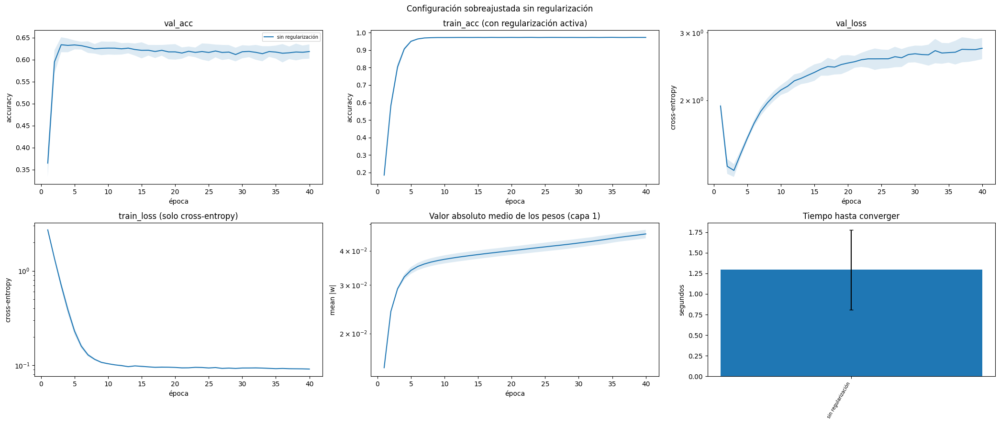

In [9]:
mlflow.end_run()
baseline_curves = sweep("referencia", {REF: BASE_CONFIG})
tbl_ref = sweep_table(baseline_curves)
tbl_ref.to_csv(f"{RESULTS_DIR}/sweep_referencia.csv")
display(tbl_ref.T)
plot_sweep(baseline_curves, "Configuración sobreajustada sin regularización")

### 6.2 Regularización L2

Se barre λ2 en escala logarítmica (pasos de ≈3×) desde un valor casi inocuo hasta uno que debería producir underfitting. La penalidad se aplica sobre los pesos de todas las capas lineales con un mismo λ. Se observa:

- si λ muy chico mantiene el sobreajuste y λ muy grande lo reemplaza por underfitting (caída de `train_acc`);
- el rango de λ en el que el rendimiento es bueno;
- la evolución del valor absoluto medio de los pesos y la forma de su distribución (la distribución debería concentrarse alrededor de 0 sin generar ceros exactos);
- el costo en tiempo por época de calcular la penalidad.

  l2 | l2=1e-06: listo
  l2 | l2=3e-06: listo
  l2 | l2=1e-05: listo
  l2 | l2=3e-05: listo
  l2 | l2=0.0001: listo
  l2 | l2=0.0003: listo
  l2 | l2=0.001: listo
  l2 | l2=0.003: listo


,mejor val_acc,mejor época,val_acc final,train_acc final,gap final (train - val),val_loss final / mín,época de convergencia,tiempo hasta converger (s),s/época,mean |w| capa 1,mean |w| salida,% pesos |w|≤1e-3,ruido train_acc,ruido val_acc,diverge
variante,,,,,,,,,,,,,,,
sin regularización,0.6372 ± 0.0122,3.7 ± 0.9,0.6184 ± 0.0162,0.9724 ± 0.0007,0.3541 ± 0.0157,2.08 ± 0.10,3.7 ± 0.9,1.29 ± 0.48,0.312 ± 0.005,0.04606 ± 0.00166,0.14755 ± 0.00228,1.5 ± 0.1,0.0018 ± 0.0002,0.0031 ± 0.0001,False
l2=1e-06,0.6254 ± 0.0146,4.7 ± 1.2,0.5923 ± 0.0075,0.9719 ± 0.0003,0.3797 ± 0.0072,2.24 ± 0.04,4.3 ± 0.9,1.74 ± 0.40,0.411 ± 0.005,0.03477 ± 0.00098,0.11262 ± 0.00737,13.9 ± 1.5,0.0019 ± 0.0003,0.0034 ± 0.0001,False
l2=3e-06,0.6263 ± 0.0123,5.0 ± 1.4,0.5805 ± 0.0030,0.9719 ± 0.0003,0.3914 ± 0.0027,2.33 ± 0.07,4.7 ± 1.2,2.05 ± 0.63,0.414 ± 0.001,0.02934 ± 0.00049,0.11639 ± 0.00619,17.5 ± 1.0,0.0019 ± 0.0003,0.0034 ± 0.0002,False
l2=1e-05,0.6170 ± 0.0144,6.0 ± 0.8,0.5678 ± 0.0045,0.9714 ± 0.0009,0.4036 ± 0.0038,2.31 ± 0.11,4.7 ± 1.2,1.89 ± 0.51,0.417 ± 0.005,0.02268 ± 0.00037,0.12275 ± 0.00671,23.0 ± 2.4,0.0021 ± 0.0002,0.0033 ± 0.0004,False
l2=3e-05,0.6069 ± 0.0221,5.0 ± 0.0,0.5696 ± 0.0071,0.9724 ± 0.0006,0.4028 ± 0.0066,2.33 ± 0.07,5.0 ± 0.0,2.06 ± 0.07,0.415 ± 0.005,0.01862 ± 0.00113,0.12916 ± 0.00679,28.4 ± 1.6,0.0024 ± 0.0001,0.0027 ± 0.0003,False
l2=0.0001,0.5776 ± 0.0188,5.3 ± 0.5,0.5668 ± 0.0215,0.9711 ± 0.0003,0.4043 ± 0.0213,1.73 ± 0.08,5.3 ± 0.5,2.33 ± 0.33,0.464 ± 0.055,0.01175 ± 0.00054,0.13364 ± 0.00763,32.1 ± 1.0,0.0027 ± 0.0002,0.0034 ± 0.0005,False
l2=0.0003,0.5525 ± 0.0300,37.7 ± 3.3,0.5518 ± 0.0311,0.9648 ± 0.0022,0.4130 ± 0.0290,1.45 ± 0.14,36.0 ± 2.9,15.07 ± 1.31,0.416 ± 0.006,0.01067 ± 0.00028,0.14360 ± 0.00472,33.8 ± 1.5,0.0020 ± 0.0002,0.0046 ± 0.0008,False
l2=0.001,0.3355 ± 0.1998,26.3 ± 15.8,0.3323 ± 0.1978,0.6313 ± 0.4118,0.2990 ± 0.2141,1.08 ± 0.06,23.0 ± 15.6,9.72 ± 6.63,0.418 ± 0.004,0.00560 ± 0.00396,0.08735 ± 0.06077,59.1 ± 28.9,0.0024 ± 0.0009,0.0041 ± 0.0028,False
l2=0.003,0.0530 ± 0.0000,6.3 ± 7.5,0.0530 ± 0.0000,0.0506 ± 0.0019,-0.0024 ± 0.0019,1.00 ± 0.00,1.0 ± 0.0,0.41 ± 0.02,0.417 ± 0.002,0.00001 ± 0.00000,0.00004 ± 0.00003,100.0 ± 0.0,0.0012 ± 0.0002,0.0001 ± 0.0000,False


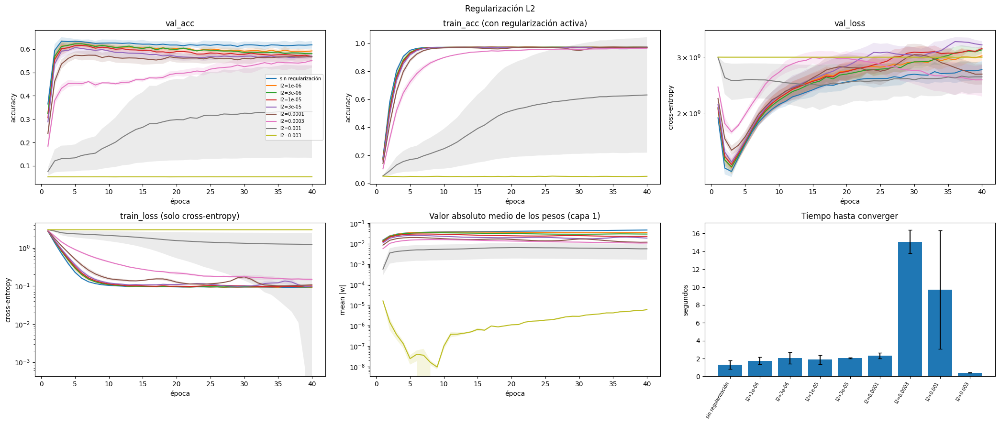

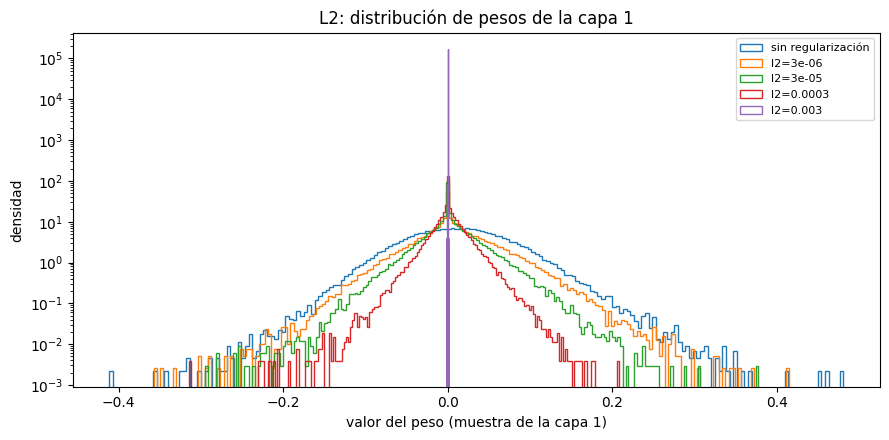

In [10]:
L2_VALUES = [1e-6, 3e-6, 1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3]
variants_l2 = {f"l2={v:g}": variant(l2=v) for v in L2_VALUES}
curves_l2 = {REF: baseline_curves[REF], **sweep("l2", variants_l2)}
tbl_l2 = sweep_table(curves_l2)
tbl_l2.to_csv(f"{RESULTS_DIR}/sweep_l2.csv")
display(tbl_l2)
plot_sweep(curves_l2, "Regularización L2")
pick = list(curves_l2.keys())[::2]
plot_weight_hist({k: curves_l2[k][0]["w_sample"] for k in pick}, "L2: distribución de pesos de la capa 1")

### 6.3 Regularización L1 y poda por magnitud

Se barre λ1 en escala logarítmica. Como L1 aplica un paso constante hacia 0 sobre cada peso, se espera que aumente la fracción de pesos casi nulos. Con Adam, el paso efectivo depende del `lr`, por lo que los pesos pueden oscilar alrededor de 0 en lugar de quedar exactamente en 0; por eso se mide la fracción de pesos con `|w| ≤ 1e-3`.

Para evaluar si L1 funciona como selector de parámetros se hace un experimento de **poda por magnitud**: con el modelo entrenado (semilla 42, sin early stopping), se anulan todos los pesos con `|w|` menor a un umbral y se mide la `val_acc` sin reentrenar. Se compara el modelo sin regularización, el mejor con L2 y el mejor con L1: si L1 concentra la información en pocos pesos, debería tolerar más poda.

  l1 | l1=1e-07: listo
  l1 | l1=3e-07: listo
  l1 | l1=1e-06: listo
  l1 | l1=3e-06: listo
  l1 | l1=1e-05: listo
  l1 | l1=3e-05: listo
  l1 | l1=0.0001: listo


,mejor val_acc,mejor época,val_acc final,train_acc final,gap final (train - val),val_loss final / mín,época de convergencia,tiempo hasta converger (s),s/época,mean |w| capa 1,mean |w| salida,% pesos |w|≤1e-3,ruido train_acc,ruido val_acc,diverge
variante,,,,,,,,,,,,,,,
sin regularización,0.6372 ± 0.0122,3.7 ± 0.9,0.6184 ± 0.0162,0.9724 ± 0.0007,0.3541 ± 0.0157,2.08 ± 0.10,3.7 ± 0.9,1.29 ± 0.48,0.312 ± 0.005,0.04606 ± 0.00166,0.14755 ± 0.00228,1.5 ± 0.1,0.0018 ± 0.0002,0.0031 ± 0.0001,False
l1=1e-07,0.6231 ± 0.0108,4.7 ± 1.2,0.5887 ± 0.0060,0.9720 ± 0.0005,0.3833 ± 0.0057,2.28 ± 0.07,4.3 ± 0.9,1.68 ± 0.36,0.399 ± 0.005,0.03217 ± 0.00061,0.10961 ± 0.00606,35.5 ± 0.2,0.0020 ± 0.0003,0.0032 ± 0.0007,False
l1=3e-07,0.6182 ± 0.0143,6.3 ± 0.5,0.5814 ± 0.0066,0.9723 ± 0.0002,0.3909 ± 0.0063,2.35 ± 0.06,4.7 ± 1.2,2.01 ± 0.62,0.403 ± 0.005,0.02553 ± 0.00119,0.11352 ± 0.00625,45.7 ± 0.5,0.0021 ± 0.0001,0.0026 ± 0.0006,False
l1=1e-06,0.6054 ± 0.0171,15.3 ± 13.9,0.5817 ± 0.0016,0.9721 ± 0.0006,0.3904 ± 0.0015,2.37 ± 0.02,5.7 ± 0.9,2.30 ± 0.33,0.403 ± 0.003,0.01778 ± 0.00075,0.11494 ± 0.00705,57.8 ± 2.1,0.0022 ± 0.0002,0.0031 ± 0.0002,False
l1=3e-06,0.5907 ± 0.0127,18.0 ± 11.5,0.5831 ± 0.0073,0.9686 ± 0.0022,0.3854 ± 0.0069,2.36 ± 0.06,16.0 ± 12.2,6.44 ± 4.93,0.402 ± 0.001,0.01580 ± 0.00039,0.12065 ± 0.00789,55.4 ± 0.4,0.0027 ± 0.0002,0.0032 ± 0.0001,False
l1=1e-05,0.5628 ± 0.0143,38.3 ± 1.2,0.5575 ± 0.0183,0.9725 ± 0.0001,0.4150 ± 0.0184,2.09 ± 0.10,36.3 ± 0.5,14.58 ± 0.12,0.404 ± 0.004,0.00928 ± 0.00096,0.12180 ± 0.00850,73.6 ± 2.2,0.0029 ± 0.0004,0.0036 ± 0.0011,False
l1=3e-05,0.4512 ± 0.0042,33.0 ± 2.8,0.4441 ± 0.0056,0.9507 ± 0.0038,0.5066 ± 0.0090,2.08 ± 0.09,25.7 ± 8.5,10.63 ± 3.34,0.412 ± 0.006,0.00677 ± 0.00013,0.13191 ± 0.00655,75.2 ± 1.1,0.0028 ± 0.0005,0.0061 ± 0.0015,False
l1=0.0001,0.0530 ± 0.0000,2.0 ± 1.4,0.0530 ± 0.0000,0.0502 ± 0.0010,-0.0028 ± 0.0010,1.00 ± 0.00,1.0 ± 0.0,0.39 ± 0.01,0.413 ± 0.006,0.00012 ± 0.00000,0.00190 ± 0.00042,100.0 ± 0.0,0.0012 ± 0.0001,0.0002 ± 0.0001,False


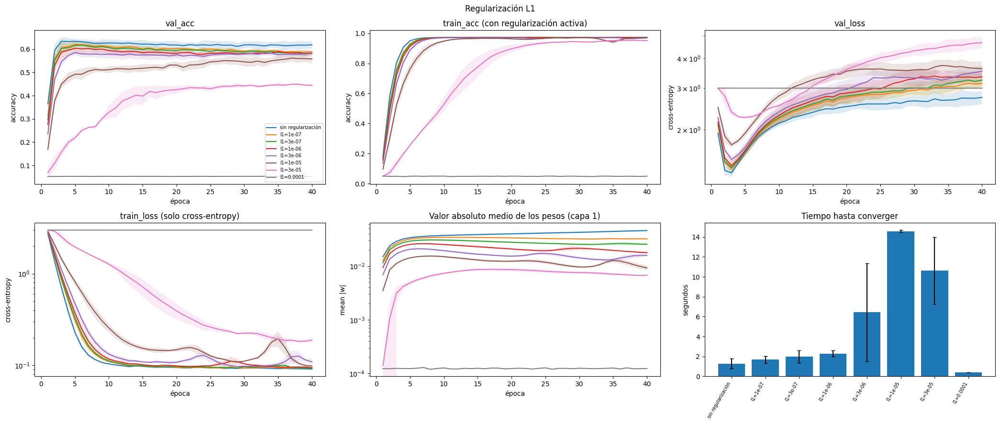

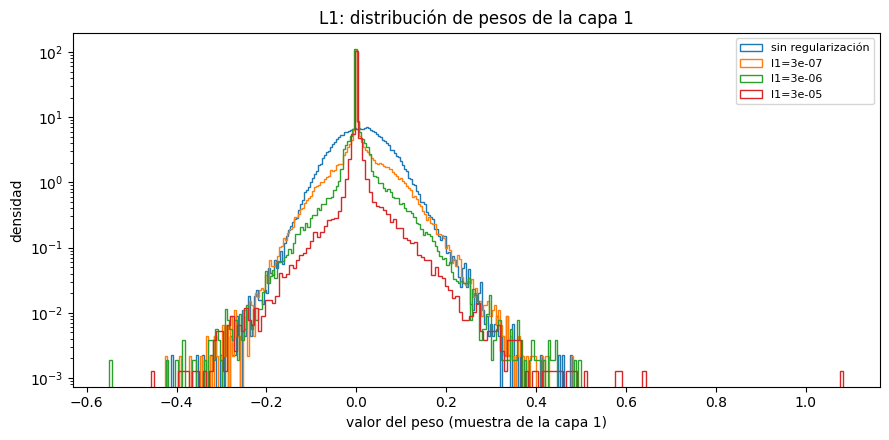

,técnica,umbral |w|,% pesos en cero,val_acc
0,sin regularización,0.0000,0.0000,0.5961
1,sin regularización,0.0001,0.1368,0.5961
2,sin regularización,0.0003,0.3993,0.5961
3,sin regularización,0.0010,1.3171,0.5961
4,sin regularización,0.0030,3.9596,0.5952
5,sin regularización,0.0100,13.0918,0.5970
6,l2=3e-06,0.0000,0.0000,0.5762
7,l2=3e-06,0.0001,13.0909,0.5762
8,l2=3e-06,0.0003,15.2336,0.5762
9,l2=3e-06,0.0010,18.9250,0.5767


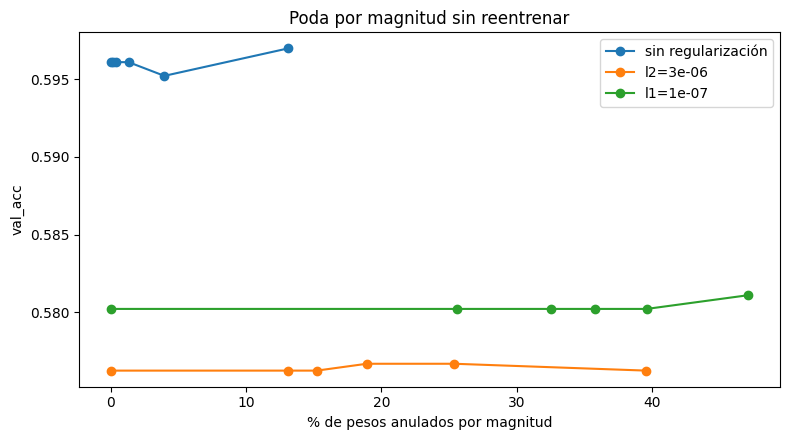

In [11]:
L1_VALUES = [1e-7, 3e-7, 1e-6, 3e-6, 1e-5, 3e-5, 1e-4]
variants_l1 = {f"l1={v:g}": variant(l1=v) for v in L1_VALUES}
curves_l1 = {REF: baseline_curves[REF], **sweep("l1", variants_l1)}
tbl_l1 = sweep_table(curves_l1)
tbl_l1.to_csv(f"{RESULTS_DIR}/sweep_l1.csv")
display(tbl_l1)
plot_sweep(curves_l1, "Regularización L1")
pick = list(curves_l1.keys())[::2]
plot_weight_hist({k: curves_l1[k][0]["w_sample"] for k in pick}, "L1: distribución de pesos de la capa 1")

PRUNE_THRESHOLDS = [0.0, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2]
best_l2_label = best_label(curves_l2, exclude=REF)
best_l1_label = best_label(curves_l1, exclude=REF)


def prune_table(label, cfg):
    h = run_one(cfg, SEED, SWEEP_EPOCHS, f"poda_{label}", keep_model=True)
    model = h["model"]
    loader = TensorLoader(T_VAL[0], T_VAL[1], EVAL_BATCH, shuffle=False)
    rows = []
    for thr in PRUNE_THRESHOLDS:
        pruned_model = copy.deepcopy(model)
        prune_by_magnitude(pruned_model, thr)
        preds, labels = predict(pruned_model, loader)
        rows.append({"técnica": label, "umbral |w|": thr,
                     "% pesos en cero": 100 * weight_sparsity(pruned_model, 0.0),
                     "val_acc": accuracy_score(labels, preds)})
        del pruned_model
    del model, h
    free_memory()
    return pd.DataFrame(rows)


prune_df = pd.concat([
    prune_table(REF, BASE_CONFIG),
    prune_table(best_l2_label, variants_l2[best_l2_label]),
    prune_table(best_l1_label, variants_l1[best_l1_label]),
], ignore_index=True)
prune_df.to_csv(f"{RESULTS_DIR}/poda_por_magnitud.csv", index=False)
display(prune_df.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
for tecnica, g in prune_df.groupby("técnica", sort=False):
    ax.plot(g["% pesos en cero"], g["val_acc"], marker="o", label=tecnica)
ax.set(xlabel="% de pesos anulados por magnitud", ylabel="val_acc", title="Poda por magnitud sin reentrenar")
ax.legend()
plt.tight_layout()
plt.show()

### 6.4 Combinación L1 + L2

Los dos términos tienen un hiperparámetro cada uno. Se parte del mejor λ1 y del mejor λ2 hallados por separado (por `val_acc` media) y se prueba una grilla de multiplicadores (0, 0,3 y 1) sobre cada uno, excluyendo la combinación sin regularización. Permite ver si los dos efectos se suman, se compensan o si uno domina.

Mejor λ1 = 1e-07 | mejor λ2 = 3e-06
  l1_l2 | l1×0 (0.0e+00) | l2×0.3 (9.0e-07): listo
  l1_l2 | l1×0 (0.0e+00) | l2×1 (3.0e-06): listo
  l1_l2 | l1×0.3 (3.0e-08) | l2×0 (0.0e+00): listo
  l1_l2 | l1×0.3 (3.0e-08) | l2×0.3 (9.0e-07): listo
  l1_l2 | l1×0.3 (3.0e-08) | l2×1 (3.0e-06): listo
  l1_l2 | l1×1 (1.0e-07) | l2×0 (0.0e+00): listo
  l1_l2 | l1×1 (1.0e-07) | l2×0.3 (9.0e-07): listo
  l1_l2 | l1×1 (1.0e-07) | l2×1 (3.0e-06): listo


,mejor val_acc,mejor época,val_acc final,train_acc final,gap final (train - val),val_loss final / mín,época de convergencia,tiempo hasta converger (s),s/época,mean |w| capa 1,mean |w| salida,% pesos |w|≤1e-3,ruido train_acc,ruido val_acc,diverge
variante,,,,,,,,,,,,,,,
sin regularización,0.6372 ± 0.0122,3.7 ± 0.9,0.6184 ± 0.0162,0.9724 ± 0.0007,0.3541 ± 0.0157,2.08 ± 0.10,3.7 ± 0.9,1.29 ± 0.48,0.312 ± 0.005,0.04606 ± 0.00166,0.14755 ± 0.00228,1.5 ± 0.1,0.0018 ± 0.0002,0.0031 ± 0.0001,False
l1×0 (0.0e+00) | l2×0.3 (9.0e-07),0.6270 ± 0.0140,4.7 ± 1.2,0.5861 ± 0.0064,0.9720 ± 0.0006,0.3859 ± 0.0060,2.28 ± 0.00,4.3 ± 0.9,1.78 ± 0.39,0.421 ± 0.007,0.03566 ± 0.00121,0.11756 ± 0.00787,13.0 ± 1.0,0.0020 ± 0.0002,0.0038 ± 0.0008,False
l1×0 (0.0e+00) | l2×1 (3.0e-06),0.6263 ± 0.0123,5.0 ± 1.4,0.5805 ± 0.0030,0.9719 ± 0.0003,0.3914 ± 0.0027,2.33 ± 0.07,4.7 ± 1.2,2.18 ± 0.74,0.422 ± 0.009,0.02934 ± 0.00049,0.11639 ± 0.00619,17.5 ± 1.0,0.0019 ± 0.0003,0.0034 ± 0.0002,False
l1×0.3 (3.0e-08) | l2×0 (0.0e+00),0.6284 ± 0.0085,4.7 ± 1.2,0.5908 ± 0.0087,0.9723 ± 0.0005,0.3815 ± 0.0084,2.25 ± 0.05,4.7 ± 1.2,1.90 ± 0.45,0.405 ± 0.002,0.03808 ± 0.00068,0.11577 ± 0.00801,25.7 ± 1.1,0.0020 ± 0.0002,0.0034 ± 0.0003,False
l1×0.3 (3.0e-08) | l2×0.3 (9.0e-07),0.6263 ± 0.0128,4.7 ± 1.2,0.5871 ± 0.0092,0.9721 ± 0.0003,0.3850 ± 0.0089,2.27 ± 0.05,4.7 ± 1.2,2.47 ± 0.58,0.508 ± 0.003,0.03250 ± 0.00071,0.11644 ± 0.00720,24.6 ± 0.8,0.0020 ± 0.0002,0.0038 ± 0.0002,False
l1×0.3 (3.0e-08) | l2×1 (3.0e-06),0.6242 ± 0.0090,4.7 ± 1.2,0.5784 ± 0.0034,0.9720 ± 0.0004,0.3936 ± 0.0030,2.35 ± 0.10,4.7 ± 1.2,2.25 ± 0.58,0.512 ± 0.005,0.02811 ± 0.00101,0.11969 ± 0.00744,25.6 ± 1.7,0.0020 ± 0.0001,0.0036 ± 0.0002,False
l1×1 (1.0e-07) | l2×0 (0.0e+00),0.6231 ± 0.0108,4.7 ± 1.2,0.5887 ± 0.0060,0.9720 ± 0.0005,0.3833 ± 0.0057,2.28 ± 0.07,4.3 ± 0.9,1.72 ± 0.38,0.408 ± 0.003,0.03217 ± 0.00061,0.10961 ± 0.00606,35.5 ± 0.2,0.0020 ± 0.0003,0.0032 ± 0.0007,False
l1×1 (1.0e-07) | l2×0.3 (9.0e-07),0.6223 ± 0.0135,6.0 ± 0.8,0.5805 ± 0.0065,0.9722 ± 0.0005,0.3917 ± 0.0060,2.28 ± 0.06,4.7 ± 1.2,2.29 ± 0.64,0.500 ± 0.003,0.02811 ± 0.00087,0.11469 ± 0.00637,35.1 ± 0.5,0.0021 ± 0.0002,0.0033 ± 0.0009,False
l1×1 (1.0e-07) | l2×1 (3.0e-06),0.6209 ± 0.0122,5.3 ± 0.5,0.5809 ± 0.0035,0.9719 ± 0.0001,0.3909 ± 0.0034,2.37 ± 0.07,4.7 ± 1.2,2.32 ± 0.47,0.494 ± 0.004,0.02622 ± 0.00024,0.11801 ± 0.00578,32.6 ± 1.3,0.0021 ± 0.0002,0.0035 ± 0.0002,False


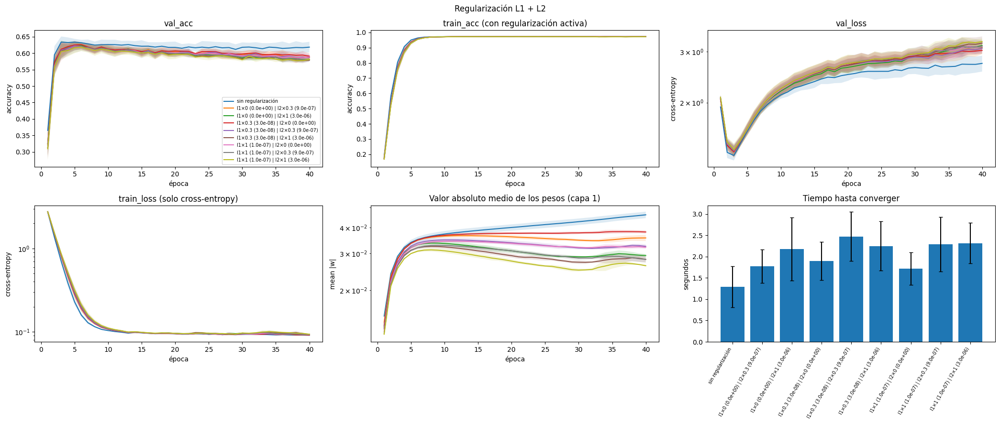

In [12]:
best_l1 = variants_l1[best_l1_label]["l1"]
best_l2 = variants_l2[best_l2_label]["l2"]
print(f"Mejor λ1 = {best_l1:g} | mejor λ2 = {best_l2:g}")

MULT = [0.0, 0.3, 1.0]
variants_l1l2 = {
    f"l1×{a:g} ({best_l1 * a:.1e}) | l2×{b:g} ({best_l2 * b:.1e})": variant(l1=best_l1 * a, l2=best_l2 * b)
    for a in MULT for b in MULT if not (a == 0.0 and b == 0.0)
}
curves_l1l2 = {REF: baseline_curves[REF], **sweep("l1_l2", variants_l1l2)}
tbl_l1l2 = sweep_table(curves_l1l2)
tbl_l1l2.to_csv(f"{RESULTS_DIR}/sweep_l1_l2.csv")
display(tbl_l1l2)
plot_sweep(curves_l1l2, "Regularización L1 + L2")

### 6.5 λ distinto por capa

Con `layer_growth = g`, la penalidad de la capa `i` (contando desde la entrada) se multiplica por `g^i`: las capas más cercanas a la salida se penalizan más. Se compara el λ2 uniforme (`g = 1`) con `g = 3` y `g = 10`, usando el mejor λ2 como λ de la primera capa. Solo tiene sentido en arquitecturas con más de una capa oculta.

  l2_por_capa | crecimiento ×3 (l2 capa 1 = 3.0e-06): listo
  l2_por_capa | crecimiento ×10 (l2 capa 1 = 3.0e-06): listo


,mejor val_acc,mejor época,val_acc final,train_acc final,gap final (train - val),val_loss final / mín,época de convergencia,tiempo hasta converger (s),s/época,mean |w| capa 1,mean |w| salida,% pesos |w|≤1e-3,ruido train_acc,ruido val_acc,diverge
variante,,,,,,,,,,,,,,,
uniforme ×1 (l2 = 3.0e-06),0.6263 ± 0.0123,5.0 ± 1.4,0.5805 ± 0.0030,0.9719 ± 0.0003,0.3914 ± 0.0027,2.33 ± 0.07,4.7 ± 1.2,2.05 ± 0.63,0.414 ± 0.001,0.02934 ± 0.00049,0.11639 ± 0.00619,17.5 ± 1.0,0.0019 ± 0.0003,0.0034 ± 0.0002,False
crecimiento ×3 (l2 capa 1 = 3.0e-06),0.6251 ± 0.0124,7.0 ± 4.3,0.5777 ± 0.0042,0.9722 ± 0.0003,0.3945 ± 0.0041,2.27 ± 0.12,4.7 ± 1.2,1.88 ± 0.51,0.416 ± 0.003,0.03089 ± 0.00081,0.11159 ± 0.00670,17.3 ± 1.0,0.0020 ± 0.0002,0.0029 ± 0.0004,False
crecimiento ×10 (l2 capa 1 = 3.0e-06),0.5986 ± 0.0180,5.7 ± 0.9,0.5777 ± 0.0308,0.9729 ± 0.0004,0.3952 ± 0.0310,1.65 ± 0.14,4.7 ± 0.5,1.92 ± 0.24,0.415 ± 0.007,0.04004 ± 0.00067,0.05053 ± 0.00151,14.7 ± 1.1,0.0023 ± 0.0003,0.0037 ± 0.0007,False


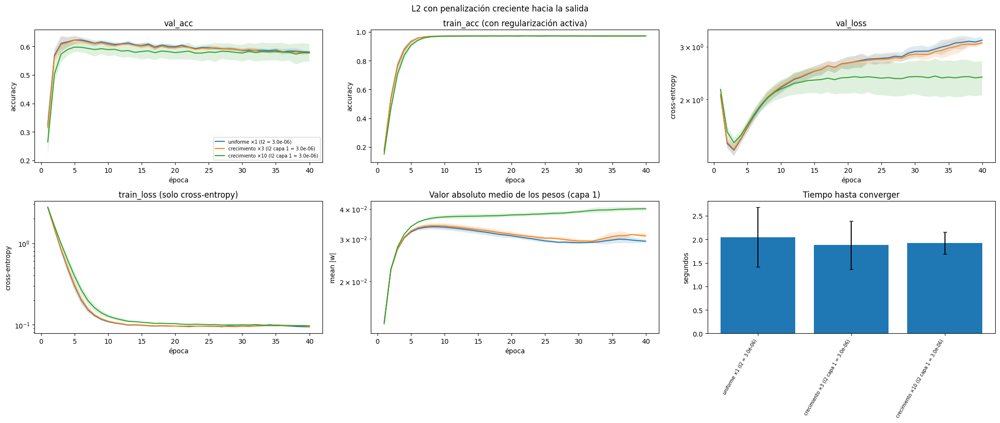

In [13]:
GROWTH_VALUES = [3.0, 10.0]
variants_growth = {f"crecimiento ×{g:g} (l2 capa 1 = {best_l2:.1e})": variant(l2=best_l2, layer_growth=g)
                   for g in GROWTH_VALUES}
curves_growth = {f"uniforme ×1 (l2 = {best_l2:.1e})": curves_l2[best_l2_label],
                 **sweep("l2_por_capa", variants_growth)}
tbl_growth = sweep_table(curves_growth)
tbl_growth.to_csv(f"{RESULTS_DIR}/sweep_l2_por_capa.csv")
display(tbl_growth)
plot_sweep(curves_growth, "L2 con penalización creciente hacia la salida")

### 6.6 Dropout

Se barre la tasa de dropout (proporción de neuronas apagadas) con dos learning rates: el de la configuración sobreajustada y ese valor ×10, ya que con dropout se recomienda un `lr` mayor. Cada entrenamiento dura `DROPOUT_EPOCHS` épocas, más que en los demás experimentos, porque los pesos de las neuronas apagadas no se actualizan en cada paso.

Se observa:
- `train_acc` y `train_loss` se miden con el dropout encendido, por lo que son más ruidosas y, al principio, peores que las de validación (que usa la red completa);
- el ruido de las curvas en función de la tasa y del `lr`;
- cuántas épocas se necesitan para converger;
- el sobreajuste residual a tasas altas;
- el valor absoluto de los pesos.

  dropout | p=0 | lr=0.001: listo
  dropout | p=0.1 | lr=0.001: listo
  dropout | p=0.2 | lr=0.001: listo
  dropout | p=0.3 | lr=0.001: listo
  dropout | p=0.5 | lr=0.001: listo
  dropout | p=0.7 | lr=0.001: listo
  dropout | p=0 | lr=0.01: listo
  dropout | p=0.1 | lr=0.01: listo
  dropout | p=0.2 | lr=0.01: listo
  dropout | p=0.3 | lr=0.01: listo
  dropout | p=0.5 | lr=0.01: listo
  dropout | p=0.7 | lr=0.01: listo


,mejor val_acc,mejor época,val_acc final,train_acc final,gap final (train - val),val_loss final / mín,época de convergencia,tiempo hasta converger (s),s/época,mean |w| capa 1,mean |w| salida,% pesos |w|≤1e-3,ruido train_acc,ruido val_acc,diverge
variante,,,,,,,,,,,,,,,
p=0 | lr=0.001,0.6372 ± 0.0122,3.7 ± 0.9,0.6092 ± 0.0094,0.9727 ± 0.0005,0.3635 ± 0.0089,2.30 ± 0.08,3.7 ± 0.9,1.16 ± 0.38,0.306 ± 0.002,0.05584 ± 0.00160,0.15150 ± 0.00429,1.3 ± 0.1,0.0014 ± 0.0002,0.0030 ± 0.0002,False
p=0.1 | lr=0.001,0.6494 ± 0.0033,13.7 ± 10.1,0.6406 ± 0.0052,0.9729 ± 0.0003,0.3323 ± 0.0053,2.93 ± 0.24,10.7 ± 9.4,3.66 ± 3.32,0.341 ± 0.001,0.05468 ± 0.00076,0.21324 ± 0.00236,1.3 ± 0.1,0.0017 ± 0.0001,0.0029 ± 0.0005,False
p=0.2 | lr=0.001,0.6655 ± 0.0070,25.3 ± 23.9,0.6546 ± 0.0078,0.9708 ± 0.0007,0.3162 ± 0.0073,2.86 ± 0.14,23.0 ± 21.3,7.80 ± 7.30,0.342 ± 0.003,0.05577 ± 0.00043,0.24552 ± 0.00701,1.4 ± 0.1,0.0021 ± 0.0001,0.0023 ± 0.0004,False
p=0.3 | lr=0.001,0.6712 ± 0.0101,42.7 ± 7.9,0.6668 ± 0.0110,0.9652 ± 0.0022,0.2984 ± 0.0123,2.49 ± 0.06,19.0 ± 5.4,6.62 ± 1.69,0.350 ± 0.004,0.05756 ± 0.00011,0.27686 ± 0.00341,1.4 ± 0.1,0.0023 ± 0.0001,0.0023 ± 0.0002,False
p=0.5 | lr=0.001,0.6836 ± 0.0042,50.7 ± 7.4,0.6796 ± 0.0069,0.9109 ± 0.0120,0.2312 ± 0.0120,1.83 ± 0.06,40.0 ± 3.7,14.01 ± 1.26,0.345 ± 0.002,0.06130 ± 0.00104,0.32778 ± 0.00311,1.6 ± 0.2,0.0028 ± 0.0004,0.0023 ± 0.0004,False
p=0.7 | lr=0.001,0.5921 ± 0.0280,51.7 ± 6.0,0.5836 ± 0.0298,0.6435 ± 0.0140,0.0599 ± 0.0159,1.32 ± 0.04,47.0 ± 4.3,16.52 ± 1.46,0.347 ± 0.001,0.05681 ± 0.00225,0.31941 ± 0.00590,2.4 ± 0.3,0.0038 ± 0.0002,0.0061 ± 0.0005,False
p=0 | lr=0.01,0.6584 ± 0.0068,34.7 ± 23.0,0.6462 ± 0.0028,0.9726 ± 0.0005,0.3264 ± 0.0024,2.51 ± 0.16,8.7 ± 8.0,2.68 ± 2.53,0.308 ± 0.001,0.23672 ± 0.01331,0.38647 ± 0.03589,2.0 ± 0.4,0.0017 ± 0.0006,0.0050 ± 0.0005,False
p=0.1 | lr=0.01,0.6706 ± 0.0030,31.0 ± 19.0,0.6625 ± 0.0050,0.9659 ± 0.0015,0.3033 ± 0.0062,2.73 ± 0.34,9.3 ± 7.6,3.17 ± 2.54,0.345 ± 0.004,0.26867 ± 0.00657,0.48373 ± 0.01428,2.1 ± 0.4,0.0013 ± 0.0001,0.0048 ± 0.0003,False
p=0.2 | lr=0.01,0.6860 ± 0.0034,43.3 ± 17.2,0.6777 ± 0.0017,0.9561 ± 0.0033,0.2783 ± 0.0047,2.27 ± 0.14,11.0 ± 7.5,3.79 ± 2.46,0.350 ± 0.004,0.29369 ± 0.00149,0.54447 ± 0.02976,2.1 ± 0.1,0.0017 ± 0.0002,0.0032 ± 0.0003,False


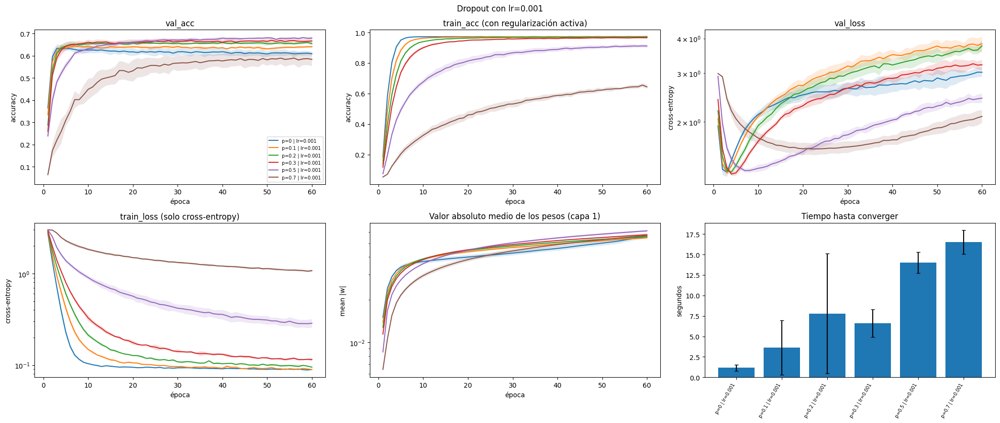

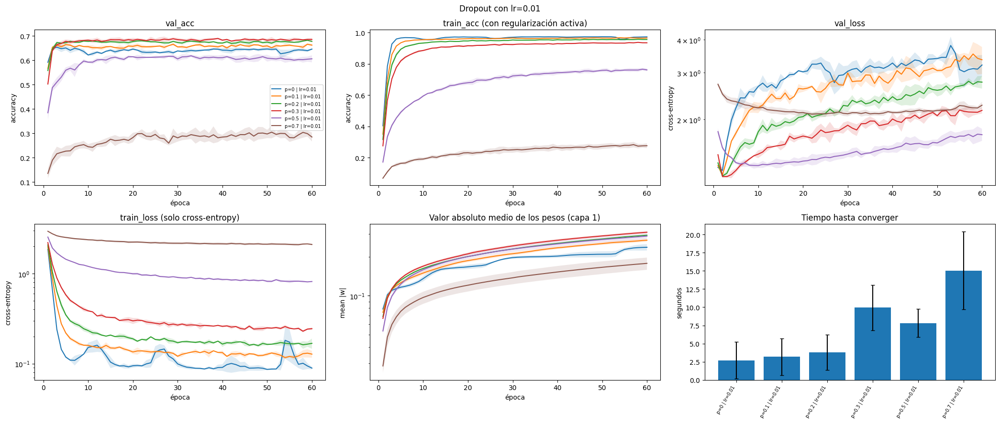

In [14]:
DROPOUT_EPOCHS = 60
DROPOUT_VALUES = [0.0, 0.1, 0.2, 0.3, 0.5, 0.7]
DROPOUT_LRS = [BASE_CONFIG["lr"], 10 * BASE_CONFIG["lr"]]
variants_do = {f"p={p:g} | lr={lr:g}": variant(dropout=p, lr=lr) for lr in DROPOUT_LRS for p in DROPOUT_VALUES}
curves_do = sweep("dropout", variants_do, epochs=DROPOUT_EPOCHS)
tbl_do = sweep_table(curves_do)
tbl_do.to_csv(f"{RESULTS_DIR}/sweep_dropout.csv")
display(tbl_do)
for lr in DROPOUT_LRS:
    keys = [k for k in curves_do if k.endswith(f"lr={lr:g}")]
    plot_sweep(subset(curves_do, keys), f"Dropout con lr={lr:g}")

### 6.7 Batch Normalization

Se compara la red con y sin BatchNorm a tres learning rates (`1e-3`, `1e-2`, `1e-1`). Se espera que BatchNorm tolere learning rates mayores y acelere la convergencia. También se prueba la combinación de dropout (0,3) con BatchNorm a `lr = 1e-2` frente a cada técnica por separado, para evaluar la recomendación de no mezclarlas.

Se observa además el costo en tiempo por época de normalizar las activaciones, el valor absoluto de los pesos y el ruido de las curvas.

  batchnorm | BN=no | lr=0.001: listo
  batchnorm | BN=sí | lr=0.001: listo
  batchnorm | BN=no | lr=0.01: listo
  batchnorm | BN=sí | lr=0.01: listo
  batchnorm | BN=no | lr=0.1: listo
  batchnorm | BN=sí | lr=0.1: listo
  batchnorm | dropout 0.3 sin BN | lr=0.01: listo
  batchnorm | dropout 0.3 + BN | lr=0.01: listo


,mejor val_acc,mejor época,val_acc final,train_acc final,gap final (train - val),val_loss final / mín,época de convergencia,tiempo hasta converger (s),s/época,mean |w| capa 1,mean |w| salida,% pesos |w|≤1e-3,ruido train_acc,ruido val_acc,diverge
variante,,,,,,,,,,,,,,,
BN=no | lr=0.001,0.6372 ± 0.0122,3.7 ± 0.9,0.6184 ± 0.0162,0.9724 ± 0.0007,0.3541 ± 0.0157,2.08 ± 0.10,3.7 ± 0.9,1.12 ± 0.33,0.308 ± 0.002,0.04606 ± 0.00166,0.14755 ± 0.00228,1.5 ± 0.1,0.0018 ± 0.0002,0.0031 ± 0.0001,False
BN=sí | lr=0.001,0.7085 ± 0.0024,2.0 ± 0.0,0.6855 ± 0.0004,0.9733 ± 0.0002,0.2878 ± 0.0003,1.47 ± 0.01,2.0 ± 0.0,0.82 ± 0.10,0.377 ± 0.004,0.02827 ± 0.00035,0.20855 ± 0.00050,2.3 ± 0.0,0.0038 ± 0.0008,0.0043 ± 0.0002,False
BN=no | lr=0.01,0.6565 ± 0.0081,14.7 ± 16.5,0.6419 ± 0.0090,0.9727 ± 0.0013,0.3308 ± 0.0079,2.55 ± 0.11,2.7 ± 0.5,0.80 ± 0.15,0.309 ± 0.002,0.20222 ± 0.00585,0.29408 ± 0.00347,2.0 ± 0.5,0.0015 ± 0.0003,0.0050 ± 0.0002,False
BN=sí | lr=0.01,0.6798 ± 0.0046,3.0 ± 0.8,0.6674 ± 0.0042,0.9685 ± 0.0025,0.3011 ± 0.0061,2.09 ± 0.15,2.0 ± 0.0,0.78 ± 0.06,0.378 ± 0.005,0.31305 ± 0.00478,0.48720 ± 0.00340,0.2 ± 0.0,0.0013 ± 0.0001,0.0040 ± 0.0004,False
BN=no | lr=0.1,0.2887 ± 0.0566,7.0 ± 3.7,0.1844 ± 0.0082,0.3176 ± 0.0538,0.1332 ± 0.0461,1.58 ± 0.14,6.7 ± 4.1,2.00 ± 1.25,0.309 ± 0.002,0.65183 ± 0.13581,1.43004 ± 0.13245,9.3 ± 0.8,0.0117 ± 0.0015,0.0125 ± 0.0009,False
BN=sí | lr=0.1,0.6518 ± 0.0006,21.7 ± 11.1,0.6384 ± 0.0040,0.9569 ± 0.0019,0.3185 ± 0.0022,3.02 ± 0.14,8.0 ± 7.1,2.99 ± 2.64,0.388 ± 0.004,3.00932 ± 0.13741,1.11817 ± 0.04955,0.7 ± 0.2,0.0027 ± 0.0002,0.0054 ± 0.0012,False
dropout 0.3 sin BN | lr=0.01,0.6955 ± 0.0044,32.7 ± 4.5,0.6829 ± 0.0043,0.9297 ± 0.0027,0.2468 ± 0.0034,1.66 ± 0.11,28.0 ± 8.6,9.89 ± 2.87,0.353 ± 0.004,0.26837 ± 0.00613,0.48323 ± 0.02806,2.3 ± 0.3,0.0026 ± 0.0003,0.0036 ± 0.0003,False
dropout 0.3 + BN | lr=0.01,0.7038 ± 0.0013,15.0 ± 9.9,0.6929 ± 0.0016,0.9420 ± 0.0016,0.2491 ± 0.0006,1.45 ± 0.03,15.0 ± 9.9,6.13 ± 4.19,0.415 ± 0.008,0.34547 ± 0.00061,0.56955 ± 0.00782,0.2 ± 0.0,0.0020 ± 0.0002,0.0032 ± 0.0004,False


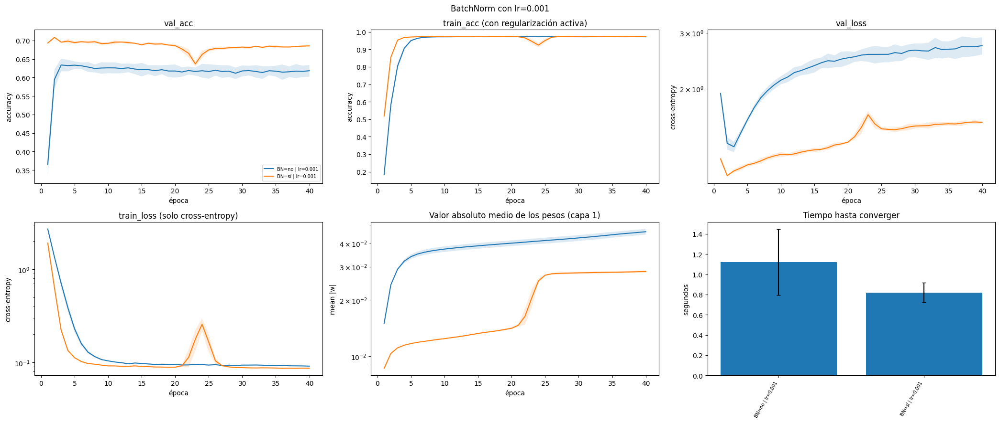

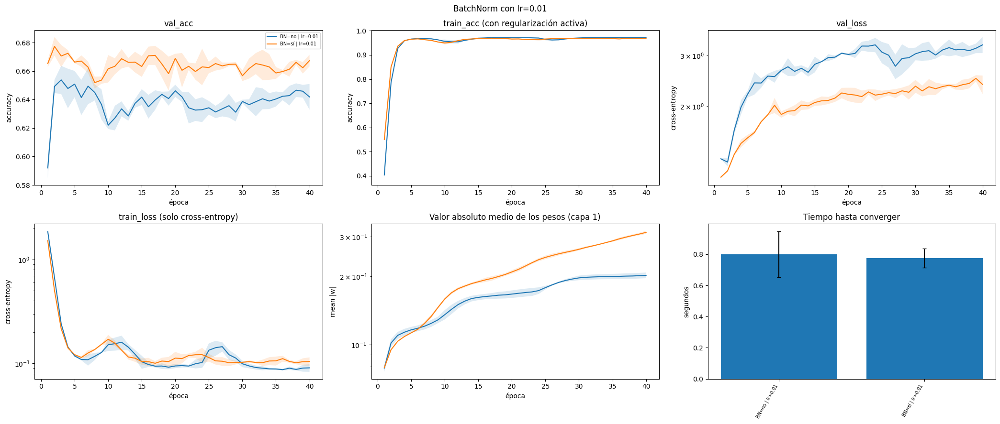

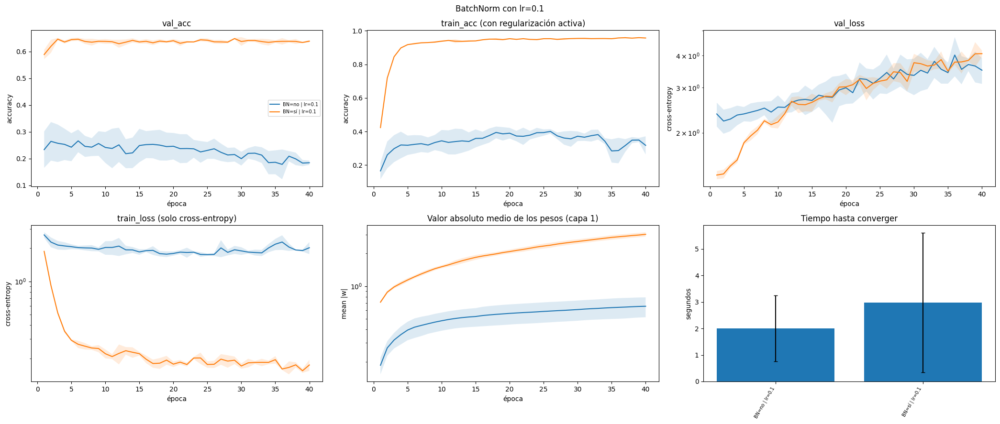

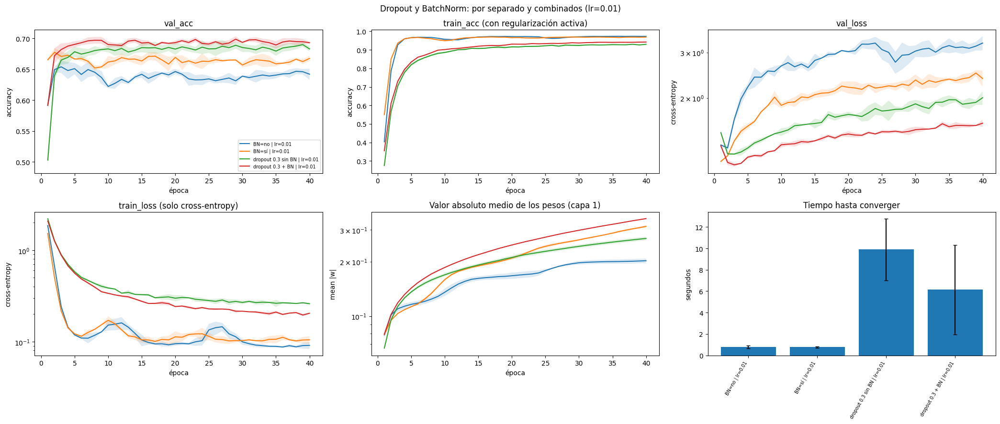

In [15]:
BN_LRS = [1e-3, 1e-2, 1e-1]
variants_bn = {f"BN={'sí' if bn else 'no'} | lr={lr:g}": variant(batch_norm=bn, lr=lr)
               for lr in BN_LRS for bn in [False, True]}
variants_bn["dropout 0.3 sin BN | lr=0.01"] = variant(dropout=0.3, lr=1e-2)
variants_bn["dropout 0.3 + BN | lr=0.01"] = variant(dropout=0.3, batch_norm=True, lr=1e-2)
curves_bn = sweep("batchnorm", variants_bn)
tbl_bn = sweep_table(curves_bn)
tbl_bn.to_csv(f"{RESULTS_DIR}/sweep_batchnorm.csv")
display(tbl_bn)
for lr in BN_LRS:
    keys = [k for k in curves_bn if k.endswith(f"lr={lr:g}") and k.startswith("BN=")]
    plot_sweep(subset(curves_bn, keys), f"BatchNorm con lr={lr:g}")
combo_keys = ["BN=no | lr=0.01", "BN=sí | lr=0.01", "dropout 0.3 sin BN | lr=0.01", "dropout 0.3 + BN | lr=0.01"]
plot_sweep(subset(curves_bn, combo_keys), "Dropout y BatchNorm: por separado y combinados (lr=0.01)")

### 6.8 Resumen por técnica

La tabla reúne, para cada técnica, la variante con mejor `val_acc` media entre semillas junto con la referencia sin regularización. Permite comparar de forma directa rendimiento, sobreajuste, pesos, ruido y tiempos.

In [16]:
summary_techniques = pd.concat({
    "sin regularización": tbl_ref.loc[[REF]],
    "L2": tbl_l2.loc[[best_label(curves_l2, exclude=REF)]],
    "L1": tbl_l1.loc[[best_label(curves_l1, exclude=REF)]],
    "L1 + L2": tbl_l1l2.loc[[best_label(curves_l1l2, exclude=REF)]],
    "Dropout": tbl_do.loc[[best_label(curves_do)]],
    "BatchNorm": tbl_bn.loc[[best_label(curves_bn)]],
}, names=["técnica", "variante"])
summary_techniques.to_csv(f"{RESULTS_DIR}/resumen_por_tecnica.csv")
display(summary_techniques)

,,mejor val_acc,mejor época,val_acc final,train_acc final,gap final (train - val),val_loss final / mín,época de convergencia,tiempo hasta converger (s),s/época,mean |w| capa 1,mean |w| salida,% pesos |w|≤1e-3,ruido train_acc,ruido val_acc,diverge
técnica,variante,,,,,,,,,,,,,,,
sin regularización,sin regularización,0.6372 ± 0.0122,3.7 ± 0.9,0.6184 ± 0.0162,0.9724 ± 0.0007,0.3541 ± 0.0157,2.08 ± 0.10,3.7 ± 0.9,1.29 ± 0.48,0.312 ± 0.005,0.04606 ± 0.00166,0.14755 ± 0.00228,1.5 ± 0.1,0.0018 ± 0.0002,0.0031 ± 0.0001,False
L2,l2=3e-06,0.6263 ± 0.0123,5.0 ± 1.4,0.5805 ± 0.0030,0.9719 ± 0.0003,0.3914 ± 0.0027,2.33 ± 0.07,4.7 ± 1.2,2.05 ± 0.63,0.414 ± 0.001,0.02934 ± 0.00049,0.11639 ± 0.00619,17.5 ± 1.0,0.0019 ± 0.0003,0.0034 ± 0.0002,False
L1,l1=1e-07,0.6231 ± 0.0108,4.7 ± 1.2,0.5887 ± 0.0060,0.9720 ± 0.0005,0.3833 ± 0.0057,2.28 ± 0.07,4.3 ± 0.9,1.68 ± 0.36,0.399 ± 0.005,0.03217 ± 0.00061,0.10961 ± 0.00606,35.5 ± 0.2,0.0020 ± 0.0003,0.0032 ± 0.0007,False
L1 + L2,l1×0.3 (3.0e-08) | l2×0 (0.0e+00),0.6284 ± 0.0085,4.7 ± 1.2,0.5908 ± 0.0087,0.9723 ± 0.0005,0.3815 ± 0.0084,2.25 ± 0.05,4.7 ± 1.2,1.90 ± 0.45,0.405 ± 0.002,0.03808 ± 0.00068,0.11577 ± 0.00801,25.7 ± 1.1,0.0020 ± 0.0002,0.0034 ± 0.0003,False
Dropout,p=0.3 | lr=0.01,0.6955 ± 0.0044,32.7 ± 4.5,0.6858 ± 0.0063,0.9349 ± 0.0027,0.2491 ± 0.0070,1.78 ± 0.05,28.0 ± 8.6,9.93 ± 3.13,0.355 ± 0.004,0.30957 ± 0.00620,0.52801 ± 0.03252,2.3 ± 0.3,0.0023 ± 0.0002,0.0035 ± 0.0001,False
BatchNorm,BN=sí | lr=0.001,0.7085 ± 0.0024,2.0 ± 0.0,0.6855 ± 0.0004,0.9733 ± 0.0002,0.2878 ± 0.0003,1.47 ± 0.01,2.0 ± 0.0,0.82 ± 0.10,0.377 ± 0.004,0.02827 ± 0.00035,0.20855 ± 0.00050,2.3 ± 0.0,0.0038 ± 0.0008,0.0043 ± 0.0002,False


In [17]:
%load_ext tensorboard
%tensorboard --logdir runs_reg

<IPython.core.display.Javascript object>

## 7. Búsqueda de hiperparámetros con Optuna (con pruning)

Los experimentos anteriores varían un factor por vez; la búsqueda explora las técnicas **en conjunto** con el `lr` y el `batch_size`.

### Diseño
- Se busca sobre **dos arquitecturas**: la configuración sobreajustada y una red más grande de tres capas de 1024 unidades (`ARCH_LIST`). Las redes grandes con regularización son una estrategia habitual.
- Para cada arquitectura hay **un estudio por tipo de regularización** (`none`, `l2`, `l1`, `l1_l2`), todos con el mismo número de trials. Así cada tipo recibe la misma exploración y la importancia de hiperparámetros no mezcla parámetros condicionales entre tipos.
- Preprocesamiento, vectorización, optimizador (Adam) y activación están fijos, para aislar el efecto de la regularización.

### Espacio de búsqueda

| Hiperparámetro | Valores |
|---|---|
| `l2` (en `l2` y `l1_l2`) | 1e-7 a 1e-2 (log) |
| `l1` (en `l1` y `l1_l2`) | 1e-8 a 1e-3 (log) |
| `dropout` | 0.0 a 0.7 (paso 0.1) |
| `batch_norm` | False, True |
| `lr` (Adam) | 1e-4 a 3e-2 (log) |
| `batch_size` | 64, 128, 256, 512 |

`dropout` y `batch_norm` se muestrean en todos los estudios, incluso en `none`, y pueden combinarse. El análisis de la sección 8 evalúa si la combinación perjudica.

### Pruning y entrenamiento
`MedianPruner` con `n_startup_trials` igual a 1/6 del presupuesto y `n_warmup_steps=3`. Cada trial entrena hasta `EPOCHS_SEARCH` épocas con early stopping (`PATIENCE`) y devuelve la mejor `val_acc`. Los estudios se guardan en `results_reg/optuna_reg.db` y se reanudan si la sesión se interrumpe.

In [18]:
ARCH_LIST = [tuple(overfit_config["hidden_units"]), (1024, 1024, 1024)]
ARCHS = {f"{len(h)}x{h[0]}": h for h in ARCH_LIST}
ARCHS_SEARCH = list(ARCHS.keys())
REG_TYPES = ["none", "l2", "l1", "l1_l2"]
EPOCHS_SEARCH = 40
PATIENCE = 6
N_TRIALS_REG = 30

REG_BOUNDS = {
    "l2": (1e-7, 1e-2, True),
    "l1": (1e-8, 1e-3, True),
    "lr": (1e-4, 3e-2, True),
    "dropout": (0.0, 0.7, False),
}
BATCH_SIZES = [64, 128, 256, 512]


def cfg_from_params(params, hidden_units):
    return {
        "hidden_units": hidden_units,
        "activation": BASE_CONFIG["activation"],
        "dropout": params.get("dropout", 0.0),
        "batch_norm": bool(params.get("batch_norm", False)),
        "l1": params.get("l1", 0.0),
        "l2": params.get("l2", 0.0),
        "layer_growth": 1.0,
        "lr": params["lr"],
        "batch_size": params["batch_size"],
    }


def suggest_cfg(trial, hidden_units, reg_type):
    p = {}
    for name in ["l2", "l1"]:
        if name in reg_type:
            low, high, log = REG_BOUNDS[name]
            p[name] = trial.suggest_float(name, low, high, log=log)
    p["dropout"] = trial.suggest_float("dropout", 0.0, 0.7, step=0.1)
    p["batch_norm"] = trial.suggest_categorical("batch_norm", [False, True])
    low, high, log = REG_BOUNDS["lr"]
    p["lr"] = trial.suggest_float("lr", low, high, log=log)
    p["batch_size"] = trial.suggest_categorical("batch_size", BATCH_SIZES)
    cfg = cfg_from_params(p, hidden_units)
    cfg["reg_type"] = reg_type
    return cfg


def make_objective(arch_name, hidden_units, reg_type, seed):
    def objective(trial):
        cfg = suggest_cfg(trial, hidden_units, reg_type)
        h = run_one(cfg, seed, EPOCHS_SEARCH, f"busq_{arch_name}_{reg_type}_t{trial.number:03d}",
                    patience=PATIENCE, trial=trial)
        return h["best_val_acc"]
    return objective


def run_search(n_trials, seed=SEED):
    while mlflow.active_run():
        mlflow.end_run()
    studies = {}
    n_startup = max(4, n_trials // 6)
    with mlflow.start_run(run_name="optuna_regularizacion"):
        for arch_name in ARCHS_SEARCH:
            for reg_type in REG_TYPES:
                key = f"{arch_name}_{reg_type}"
                study = optuna.create_study(
                    direction="maximize",
                    study_name=f"reg_{key}",
                    storage=f"sqlite:///{RESULTS_DIR}/optuna_reg.db",
                    load_if_exists=True,
                    sampler=optuna.samplers.TPESampler(seed=seed),
                    pruner=optuna.pruners.MedianPruner(n_startup_trials=n_startup, n_warmup_steps=3),
                )
                remaining = n_trials - sum(t.state.is_finished() for t in study.trials)
                if remaining > 0:
                    with mlflow.start_run(run_name=f"reg_{key}", nested=True):
                        study.optimize(make_objective(arch_name, ARCHS[arch_name], reg_type, seed),
                                       n_trials=remaining)
                studies[key] = study
    return studies


def best_by_arch(studies):
    out = {}
    for arch_name in ARCHS_SEARCH:
        keys = [f"{arch_name}_{r}" for r in REG_TYPES]
        key = max(keys, key=lambda k: studies[k].best_value)
        trial = studies[key].best_trial
        out[arch_name] = {"estudio": key, "trial": trial, "cfg": cfg_from_params(trial.params, ARCHS[arch_name])}
    return out

In [20]:
studies_reg = run_search(N_TRIALS_REG)
for key, s in studies_reg.items():
    estados = pd.Series([t.state.name for t in s.trials]).value_counts().to_dict()
    print(f"{key:12s} mejor val_acc = {s.best_value:.4f} | {estados}")

3x64_none    mejor val_acc = 0.7119 | {'COMPLETE': 22, 'PRUNED': 8}
3x64_l2      mejor val_acc = 0.7132 | {'COMPLETE': 20, 'PRUNED': 10}
3x64_l1      mejor val_acc = 0.7137 | {'COMPLETE': 18, 'PRUNED': 12}
3x64_l1_l2   mejor val_acc = 0.7141 | {'COMPLETE': 18, 'PRUNED': 12}
3x1024_none  mejor val_acc = 0.7388 | {'COMPLETE': 19, 'PRUNED': 11}
3x1024_l2    mejor val_acc = 0.7437 | {'COMPLETE': 22, 'PRUNED': 8}
3x1024_l1    mejor val_acc = 0.7424 | {'COMPLETE': 23, 'PRUNED': 7}
3x1024_l1_l2 mejor val_acc = 0.7411 | {'COMPLETE': 21, 'PRUNED': 8, 'FAIL': 1}


## 8. Análisis de la búsqueda

Se analiza toda la búsqueda, no solo el mejor trial:

1. **Pruning**: trials podados y tiempo ahorrado por estudio (el tiempo sin poda se estima como el tiempo por época de cada trial podado por las épocas medias de un trial completo).
2. **Mejor trial por estudio** y tablas por tipo de regularización, uso de BatchNorm, dropout, combinación dropout + BatchNorm y `batch_size`. Se incluyen épocas y tiempo de convergencia, segundos por época, valor absoluto medio de los pesos de la primera capa, porcentaje de pesos casi nulos y ruido de las curvas.
3. **Learning rate**: rendimiento y ruido por cuartil de `lr` y gráfico por trial, con BatchNorm distinguido.
4. **Chequeo de bordes**: si los mejores trials se acumulan en un límite del rango, no se puede asegurar un óptimo.
5. **Importancia de hiperparámetros** (fANOVA), por estudio. Es una medida correlacional que depende de la región muestreada.
6. **Historia de la optimización** de cada estudio.

In [21]:
def trials_df(studies):
    frames = []
    for key, study in studies.items():
        d = study.trials_dataframe(attrs=("number", "value", "state", "duration", "params", "user_attrs"))
        arch, reg = key.split("_", 1)
        d["arquitectura"] = arch
        d["regularizacion"] = reg
        frames.append(d)
    out = pd.concat(frames, ignore_index=True)
    out["duration_s"] = out["duration"].dt.total_seconds()
    out["s_per_epoch"] = out["user_attrs_train_time"] / out["user_attrs_epochs_run"]
    out["perf"] = out["user_attrs_best_val_acc"]
    out = out[out["state"].isin(["COMPLETE", "PRUNED"])].reset_index(drop=True)
    return out


def pruning_report(df):
    rows = []
    for (arch, reg), g in df.groupby(["arquitectura", "regularizacion"]):
        d = g[g["state"] == "COMPLETE"]
        p = g[g["state"] == "PRUNED"]
        row = {"arquitectura": arch, "regularización": reg, "trials": len(g), "completos": len(d),
               "podados": len(p), "tiempo real de podados (s)": np.nan, "tiempo estimado sin poda (s)": np.nan}
        if len(d) and len(p):
            epoch_t = p["user_attrs_train_time"] / p["user_attrs_epochs_run"]
            row["tiempo real de podados (s)"] = float(p["user_attrs_train_time"].sum())
            row["tiempo estimado sin poda (s)"] = float((epoch_t * d["user_attrs_epochs_run"].mean()).sum())
        rows.append(row)
    out = pd.DataFrame(rows)
    total = {"arquitectura": "total", "regularización": "", "trials": out["trials"].sum(),
             "completos": out["completos"].sum(), "podados": out["podados"].sum(),
             "tiempo real de podados (s)": out["tiempo real de podados (s)"].sum(),
             "tiempo estimado sin poda (s)": out["tiempo estimado sin poda (s)"].sum()}
    out = pd.concat([out, pd.DataFrame([total])], ignore_index=True)
    out["ahorro (s)"] = out["tiempo estimado sin poda (s)"] - out["tiempo real de podados (s)"]
    out["ahorro (%)"] = 100 * out["ahorro (s)"] / out["tiempo estimado sin poda (s)"]
    return out.round(1)


def summary_by(df, cols, value_col="value"):
    g = df.groupby(cols, observed=True).agg(
        n=(value_col, "count"),
        val_acc_media=(value_col, "mean"),
        val_acc_std=(value_col, "std"),
        val_acc_max=(value_col, "max"),
        epoca_conv_media=("user_attrs_conv_epoch", "mean"),
        tiempo_conv_medio_s=("user_attrs_conv_time", "mean"),
        s_por_epoca=("s_per_epoch", "mean"),
        w_abs_capa1_media=("user_attrs_w_abs_capa1", "mean"),
        pesos_casi_nulos_pct=("user_attrs_sparsity_pct", "mean"),
        ruido_train_acc=("user_attrs_noise_train_acc", "mean"),
        ruido_val_acc=("user_attrs_noise_val_acc", "mean"),
    )
    return g.round(4)


df_reg = trials_df(studies_reg)
df_reg.to_csv(f"{RESULTS_DIR}/trials_regularizacion.csv", index=False)
done = df_reg[df_reg["state"] == "COMPLETE"].copy()
done["params_batch_norm"] = done["params_batch_norm"].astype(bool)
done["dropout_y_bn"] = np.select(
    [(done["params_dropout"] > 0) & done["params_batch_norm"],
     (done["params_dropout"] > 0) & ~done["params_batch_norm"],
     (done["params_dropout"] == 0) & done["params_batch_norm"]],
    ["dropout + BN", "solo dropout", "solo BN"], default="ninguno")

print(f"Trials: {len(df_reg)} | completos: {len(done)} | podados: {(df_reg['state'] == 'PRUNED').sum()}")
print("\nPruning por estudio:")
pruning_tbl = pruning_report(df_reg)
pruning_tbl.to_csv(f"{RESULTS_DIR}/pruning_regularizacion.csv", index=False)
display(pruning_tbl)

best_tbl = pd.DataFrame([{
    "estudio": k, "mejor val_acc": s.best_value, "mejor época": s.best_trial.user_attrs["best_epoch"],
    "época de convergencia": s.best_trial.user_attrs["conv_epoch"],
    "tiempo hasta converger (s)": s.best_trial.user_attrs["conv_time"],
    "s/época": s.best_trial.user_attrs["train_time"] / s.best_trial.user_attrs["epochs_run"],
    "mean |w| capa 1": s.best_trial.user_attrs.get("w_abs_capa1"),
    "% pesos casi nulos": s.best_trial.user_attrs.get("sparsity_pct"),
    "ruido val_acc": s.best_trial.user_attrs.get("noise_val_acc"),
    **s.best_trial.params,
} for k, s in studies_reg.items()]).set_index("estudio")
best_tbl.to_csv(f"{RESULTS_DIR}/mejor_por_estudio.csv")
print("\nMejor trial de cada estudio:")
display(best_tbl.round(5))

group_cols = ["regularizacion", "params_batch_norm", "dropout_y_bn", "params_dropout", "params_batch_size"]
group_tables = {}
for col in group_cols:
    group_tables[col] = summary_by(done, ["arquitectura", col])
    print(f"\n--- por {col.replace('params_', '')} (trials completos) ---")
    display(group_tables[col])
pd.concat(group_tables, names=["hiperparámetro"]).to_csv(f"{RESULTS_DIR}/resumen_por_hiperparametro_reg.csv")

Trials: 239 | completos: 163 | podados: 76

Pruning por estudio:


,arquitectura,regularización,trials,completos,podados,tiempo real de podados (s),tiempo estimado sin poda (s),ahorro (s),ahorro (%)
0,3x1024,l1,30,23,7,17.7,51.8,34.2,65.9
1,3x1024,l1_l2,29,21,8,31.2,80.2,49.0,61.1
2,3x1024,l2,30,22,8,21.9,60.0,38.2,63.6
3,3x1024,none,30,19,11,38.2,85.5,47.3,55.4
4,3x64,l1,30,18,12,12.3,57.1,44.8,78.4
5,3x64,l1_l2,30,18,12,12.0,31.4,19.4,61.7
6,3x64,l2,30,20,10,22.2,83.9,61.6,73.5
7,3x64,none,30,22,8,6.5,17.6,11.1,62.9
8,total,,239,163,76,162.0,467.5,305.5,65.3



Mejor trial de cada estudio:


,mejor val_acc,mejor época,época de convergencia,tiempo hasta converger (s),s/época,mean |w| capa 1,% pesos casi nulos,ruido val_acc,dropout,batch_norm,lr,batch_size,l2,l1
estudio,,,,,,,,,,,,,,
3x64_none,0.71189,5,5,1.01079,0.20373,0.01286,5.33598,0.00282,0.3,True,0.00088,128,NaN,NaN
3x64_l2,0.71321,3,3,1.80822,0.55958,0.00643,23.28015,0.00493,0.3,True,0.00081,64,0.00336,NaN
3x64_l1,0.71365,16,12,1.55193,0.13137,0.01798,19.55583,0.00176,0.4,True,0.00190,256,NaN,0.00000
3x64_l1_l2,0.71410,4,4,0.60054,0.15623,0.00323,44.56483,0.00122,0.2,True,0.00063,256,0.00001,0.00003
3x1024_none,0.73884,12,7,2.43217,0.34827,0.02055,2.69080,0.00178,0.6,True,0.00295,512,NaN,NaN
3x1024_l2,0.74370,5,5,3.23323,0.64764,0.01037,5.96067,0.00438,0.7,True,0.00116,256,0.00000,NaN
3x1024_l1,0.74238,5,5,3.14542,0.63015,0.00932,8.26131,0.00361,0.7,True,0.00104,256,NaN,0.00000
3x1024_l1_l2,0.74105,4,4,3.15402,0.78816,0.00209,36.31990,0.00217,0.5,True,0.00022,256,0.00087,0.00000



--- por regularizacion (trials completos) ---


n  val_acc_media  val_acc_std  val_acc_max  \
arquitectura regularizacion                                                
3x1024       l1              23         0.6870       0.1440       0.7424   
             l1_l2           21         0.6566       0.2023       0.7411   
             l2              22         0.7092       0.0628       0.7437   
             none            19         0.7043       0.0800       0.7388   
3x64         l1              18         0.6356       0.1624       0.7137   
             l1_l2           18         0.6262       0.2097       0.7141   
             l2              20         0.6629       0.0888       0.7132   
             none            22         0.6864       0.0381       0.7119   

                             epoca_conv_media  tiempo_conv_medio_s  \
arquitectura regularizacion                                          
3x1024       l1                        4.8696               3.4654   
             l1_l2                     3.4286               2.8681   
             l2                        4.5000               3.1240   
             none                      3.6316               1.7513   
3x64         l1                       12.3333               1.9727   
             l1_l2                     3.5000               0.5526   
             l2                       11.5500               2.5965   
             none                      5.7727               1.2433   

                             s_por_epoca  w_abs_capa1_media  \
arquitectura regularizacion                                   
3x1024       l1                   0.8267             0.0129   
             l1_l2                0.9179             0.0035   
             l2                   0.7707             0.0082   
             none                 0.5789             0.0571   
3x64         l1                   0.2761             0.0217   
             l1_l2                0.1709             0.0109   
             l2                   0.3712             0.0199   
             none                 0.1860             0.0711   

                             pesos_casi_nulos_pct  ruido_train_acc  \
arquitectura regularizacion                                          
3x1024       l1                           29.3024           0.0024   
             l1_l2                        53.6735           0.0056   
             l2                           21.5889           0.0028   
             none                          2.9514           0.0017   
3x64         l1                           33.1321           0.0035   
             l1_l2                        38.0323           0.0031   
             l2                           13.9703           0.0033   
             none                          2.4114           0.0020   

                             ruido_val_acc  
arquitectura regularizacion                 
3x1024       l1                     0.0025  
             l1_l2                  0.0031  
             l2                     0.0028  
             none                   0.0025  
3x64         l1                     0.0033  
             l1_l2                  0.0026  
             l2                     0.0038  
             none                   0.0028

... (4 outputs left out)


--- por dropout (trials completos) ---


n  val_acc_media  val_acc_std  val_acc_max  \
arquitectura params_dropout                                                
3x1024       0.0             10         0.5965       0.2068       0.7274   
             0.1              2         0.7309       0.0037       0.7335   
             0.2             12         0.6960       0.0382       0.7349   
             0.3              4         0.7265       0.0117       0.7353   
             0.4              9         0.6918       0.1173       0.7366   
             0.5             16         0.6911       0.1704       0.7428   
             0.6             15         0.6831       0.1748       0.7411   
             0.7             17         0.7271       0.0288       0.7437   
3x64         0.0             17         0.6265       0.1601       0.7057   
             0.1             10         0.6996       0.0102       0.7106   
             0.2             23         0.6888       0.0301       0.7141   
             0.3             13         0.7056       0.0086       0.7132   
             0.4              8         0.6852       0.0619       0.7137   
             0.5              2         0.3774       0.4587       0.7017   
             0.6              3         0.4599       0.3526       0.6779   
             0.7              2         0.3957       0.0034       0.3981   

                             epoca_conv_media  tiempo_conv_medio_s  \
arquitectura params_dropout                                          
3x1024       0.0                       4.0000               2.3892   
             0.1                       4.0000               3.1483   
             0.2                       3.8333               3.2366   
             0.3                       3.0000               2.1546   
             0.4                       2.6667               2.0539   
             0.5                       3.3750               2.1615   
             0.6                       4.0667               2.5366   
             0.7                       6.2941               4.3042   
3x64         0.0                       8.3529               1.0803   
             0.1                       2.5000               0.5588   
             0.2                       7.5652               1.5897   
             0.3                       5.6154               1.3895   
             0.4                      11.3750               3.3874   
             0.5                       6.5000               3.2847   
             0.6                      16.6667               1.3463   
             0.7                      37.5000               4.2248   

                             s_por_epoca  w_abs_capa1_media  \
arquitectura params_dropout                                   
3x1024       0.0                  0.6224             0.0245   
             0.1                  0.7882             0.0017   
             0.2                  0.9771             0.0081   
             0.3                  0.9722             0.0065   
             0.4                  0.8700             0.0202   
             0.5                  0.6845             0.0191   
             0.6                  0.7744             0.0276   
             0.7                  0.7310             0.0213   
3x64         0.0                  0.1944             0.0259   
             0.1                  0.2432             0.0364   
             0.2                  0.2591             0.0287   
             0.3                  0.3092             0.0194   
             0.4                  0.2994             0.0757   
             0.5                  0.3993             0.0053   
             0.6                  0.1414             0.0640   
             0.7                  0.1129             0.0131   

                             pesos_casi_nulos_pct  ruido_train_acc  \
arquitectura params_dropout                                          
3x1024       0.0                          39.3960           0.0059   
             0.1                          45.6324      


--- por batch_size (trials completos) ---


n  val_acc_media  val_acc_std  val_acc_max  \
arquitectura params_batch_size                                                
3x1024       64                  8         0.6748       0.1202       0.7335   
             128                10         0.5894       0.2835       0.7411   
             256                55         0.7185       0.0345       0.7437   
             512                12         0.6472       0.2023       0.7388   
3x64         64                 23         0.6923       0.0384       0.7132   
             128                11         0.5776       0.2599       0.7119   
             256                39         0.6741       0.0732       0.7141   
             512                 5         0.5004       0.2635       0.6779   

                                epoca_conv_media  tiempo_conv_medio_s  \
arquitectura params_batch_size                                          
3x1024       64                           2.0000               3.6382   
             128                          2.5000               2.6527   
             256                          4.3636               2.8676   
             512                          5.9167               2.3820   
3x64         64                           6.1739               2.8611   
             128                          3.6364               0.7724   
             256                          9.2051               1.1166   
             512                         20.4000               1.3778   

                                s_por_epoca  w_abs_capa1_media  \
arquitectura params_batch_size                                   
3x1024       64                      1.7823             0.0240   
             128                     1.0941             0.0085   
             256                     0.6583             0.0188   
             512                     0.4029             0.0270   
3x64         64                      0.5025             0.0323   
             128                     0.2221             0.0434   
             256                     0.1342             0.0272   
             512                     0.0655             0.0537   

                                pesos_casi_nulos_pct  ruido_train_acc  \
arquitectura params_batch_size                                          
3x1024       64                              28.2479           0.0015   
             128                             40.6974           0.0019   
             256                             26.6058           0.0038   
             512                             19.6547           0.0021   
3x64         64                              19.8201           0.0032   
             128                             25.9546           0.0024   
             256                             19.2783           0.0028   
             512                             24.0402           0.0043   

                                ruido_val_acc  
arquitectura params_batch_size                 
3x1024       64                        0.0023  
             128                       0.0025  
             256                       0.0029  
             512                       0.0026  
3x64         64                        0.0034  
             128                       0.0028  
             256                       0.0029  
             512                       0.0043

--- 3x64: por cuartil de lr (todos los trials; val_acc = mejor alcanzada) ---


,n,val_acc_media,val_acc_std,val_acc_max,epoca_conv_media,tiempo_conv_medio_s,s_por_epoca,w_abs_capa1_media,pesos_casi_nulos_pct,ruido_train_acc,ruido_val_acc
cuartil de lr,,,,,,,,,,,
"(-0.000896, 0.000336]",31,0.4530,0.2591,0.7119,9.3871,1.5943,0.2712,0.0085,33.8870,0.0038,0.0035
"(0.000336, 0.000842]",29,0.6445,0.1173,0.7141,7.0000,1.6498,0.2685,0.0088,31.4487,0.0028,0.0031
"(0.000842, 0.00265]",30,0.6369,0.1534,0.7137,4.4333,1.1874,0.2870,0.0176,12.5786,0.0027,0.0024
"(0.00265, 0.0253]",30,0.6267,0.1407,0.7106,5.8667,1.1695,0.2229,0.0860,7.6985,0.0026,0.0035


--- 3x1024: por cuartil de lr (todos los trials; val_acc = mejor alcanzada) ---


,n,val_acc_media,val_acc_std,val_acc_max,epoca_conv_media,tiempo_conv_medio_s,s_por_epoca,w_abs_capa1_media,pesos_casi_nulos_pct,ruido_train_acc,ruido_val_acc
cuartil de lr,,,,,,,,,,,
"(-0.000896, 0.000287]",31,0.6139,0.2237,0.7428,4.8710,3.5379,0.8453,0.0028,39.6144,0.0029,0.0025
"(0.000287, 0.00073]",29,0.6796,0.1368,0.7411,3.7931,2.7600,0.7673,0.0037,37.6126,0.0032,0.0032
"(0.00073, 0.00426]",29,0.7231,0.0177,0.7437,3.9310,2.4048,0.6857,0.0139,14.0745,0.0024,0.0025
"(0.00426, 0.0263]",30,0.6633,0.1391,0.7388,2.9667,2.1538,0.7538,0.0659,15.7713,0.0046,0.0027


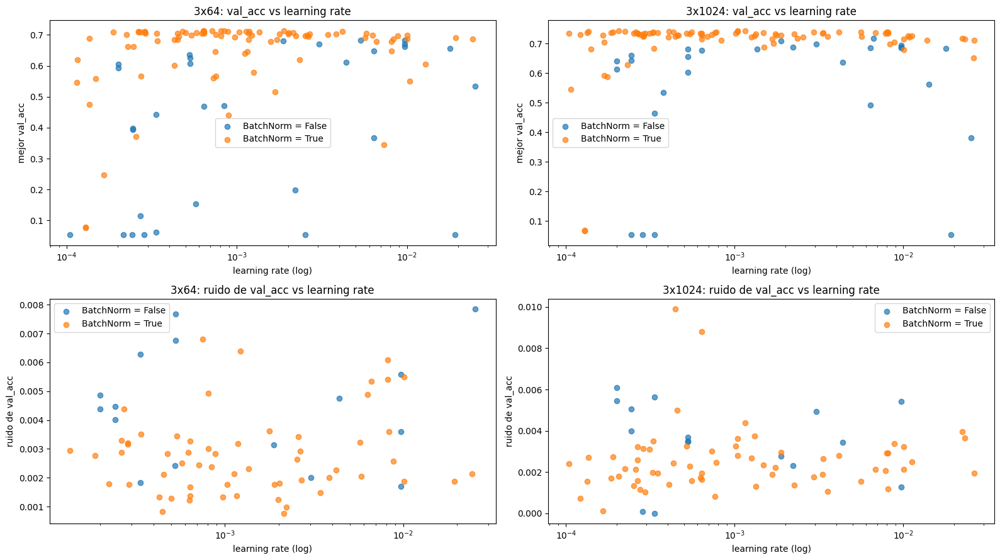

In [22]:
perf_df = df_reg[df_reg["perf"].notna()].copy()
lr_tables = {}
for arch in ARCHS_SEARCH:
    g = perf_df[perf_df["arquitectura"] == arch].copy()
    g["cuartil de lr"] = pd.qcut(g["params_lr"], 4, duplicates="drop")
    lr_tables[arch] = summary_by(g, ["cuartil de lr"], value_col="perf")
    print(f"--- {arch}: por cuartil de lr (todos los trials; val_acc = mejor alcanzada) ---")
    display(lr_tables[arch])
pd.concat(lr_tables, names=["arquitectura"]).to_csv(f"{RESULTS_DIR}/resumen_por_lr_reg.csv")

fig, axes = plt.subplots(2, len(ARCHS_SEARCH), figsize=(8 * len(ARCHS_SEARCH), 9), squeeze=False)
for c, arch in enumerate(ARCHS_SEARCH):
    g = perf_df[perf_df["arquitectura"] == arch]
    for bn, color in [(False, "tab:blue"), (True, "tab:orange")]:
        s = g[g["params_batch_norm"].astype(bool) == bn]
        axes[0, c].scatter(s["params_lr"], s["perf"], color=color, alpha=0.7, label=f"BatchNorm = {bn}")
        axes[1, c].scatter(s["params_lr"], s["user_attrs_noise_val_acc"], color=color, alpha=0.7, label=f"BatchNorm = {bn}")
    axes[0, c].set(title=f"{arch}: val_acc vs learning rate", xlabel="learning rate (log)", ylabel="mejor val_acc", xscale="log")
    axes[1, c].set(title=f"{arch}: ruido de val_acc vs learning rate", xlabel="learning rate (log)", ylabel="ruido de val_acc", xscale="log")
    axes[0, c].legend()
    axes[1, c].legend()
plt.tight_layout()
plt.show()

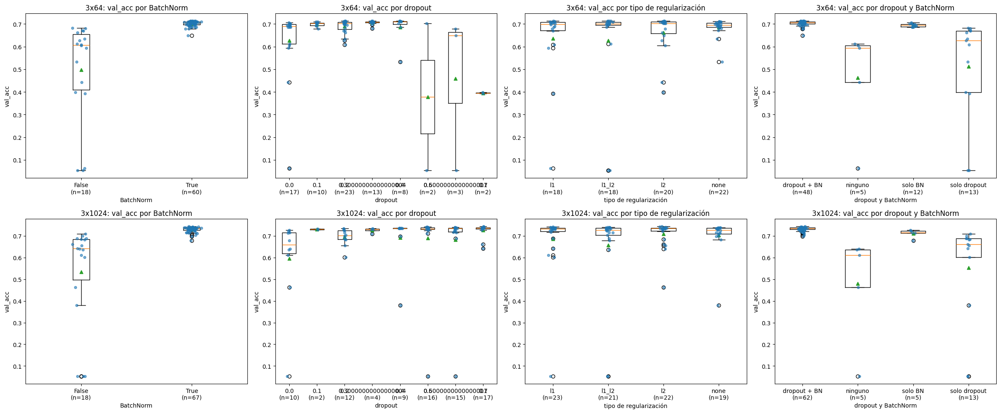

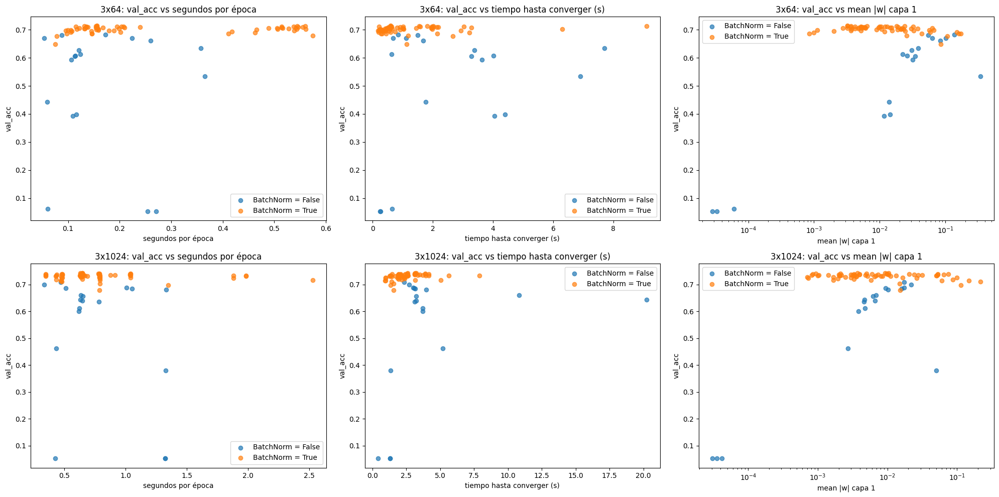

In [23]:
def group_boxplot(ax, df, col, title, xlabel, value_col="value", ylabel="val_acc"):
    cats = sorted(df[col].dropna().unique())
    data = [df.loc[df[col] == c, value_col].dropna().values for c in cats]
    ax.boxplot(data, showmeans=True)
    rng = np.random.default_rng(SEED)
    for i, d in enumerate(data, start=1):
        ax.scatter(rng.normal(i, 0.04, len(d)), d, alpha=0.6, s=18, color="tab:blue", zorder=3)
    ax.set_xticks(range(1, len(cats) + 1))
    ax.set_xticklabels([f"{c}\n(n={len(d)})" for c, d in zip(cats, data)])
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)


panels = [("params_batch_norm", "BatchNorm"), ("params_dropout", "dropout"),
          ("regularizacion", "tipo de regularización"), ("dropout_y_bn", "dropout y BatchNorm")]
fig, axes = plt.subplots(len(ARCHS_SEARCH), len(panels), figsize=(6 * len(panels), 5 * len(ARCHS_SEARCH)), squeeze=False)
for r, arch in enumerate(ARCHS_SEARCH):
    sub = done[done["arquitectura"] == arch]
    for c, (col, label) in enumerate(panels):
        group_boxplot(axes[r, c], sub, col, f"{arch}: val_acc por {label}", label)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(len(ARCHS_SEARCH), 3, figsize=(20, 5 * len(ARCHS_SEARCH)), squeeze=False)
for r, arch in enumerate(ARCHS_SEARCH):
    sub = done[done["arquitectura"] == arch]
    for c, (col, label) in enumerate([("s_per_epoch", "segundos por época"),
                                      ("user_attrs_conv_time", "tiempo hasta converger (s)"),
                                      ("user_attrs_w_abs_capa1", "mean |w| capa 1")]):
        for bn, color in [(False, "tab:blue"), (True, "tab:orange")]:
            s = sub[sub["params_batch_norm"] == bn]
            axes[r, c].scatter(s[col], s["value"], color=color, alpha=0.7, label=f"BatchNorm = {bn}")
        axes[r, c].set(title=f"{arch}: val_acc vs {label}", xlabel=label, ylabel="val_acc",
                       xscale="log" if c == 2 else "linear")
        axes[r, c].legend()
plt.tight_layout()
plt.show()

mín. observado  máx. observado  \
arquitectura regularización hiperparámetro                                   
3x1024       l1             l1                    0.000000        0.000004   
                            lr                    0.000264        0.008138   
                            dropout               0.400000        0.700000   
                            batch_size          128.000000      512.000000   
             l1_l2          l2                    0.000069        0.009420   
                            l1                    0.000000        0.000005   
                            lr                    0.000133        0.000434   
                            dropout               0.100000        0.600000   
                            batch_size          256.000000      256.000000   
             l2             l2                    0.000000        0.000131   
                            lr                    0.000185        0.004139   
                            dropout               0.200000        0.700000   
                            batch_size          256.000000      256.000000   
             none           lr                    0.000730        0.011222   
                            dropout               0.500000        0.700000   
                            batch_size          256.000000      512.000000   
3x64         l1             l1                    0.000000        0.000336   
                            lr                    0.000264        0.002685   
                            dropout               0.000000        0.400000   
                            batch_size           64.000000      256.000000   
             l1_l2          l2                    0.000000        0.002068   
                            l1                    0.000000        0.000058   
                            lr                    0.000447        0.002580   
                            dropout               0.100000        0.300000   
                            batch_size          256.000000      256.000000   
             l2             l2                    0.000000        0.004684   
                            lr                    0.000188        0.000843   
                            dropout               0.000000        0.400000   
                            batch_size           64.000000      256.000000   
             none           lr                    0.000884        0.010058   
                            dropout               0.000000        0.300000   
                            batch_size          128.000000      256.000000   

                                            cerca del límite inferior  \
arquitectura regularización hiperparámetro                              
3x1024       l1             l1                                      2   
                            lr                                      0   
                            dropout                                 0   
                            batch_size                              0   
             l1_l2          l2                                      0   
                            l1                                      0   
                            lr                                      3   
                            dropout                                 0   
                            batch_size                              0   
             l2             l2                                      0   
                            lr                                      0   
                            dropout                                 0   
                            batch_size                              0   
             none           lr                                      0   
                            dropout                                 0   
                            batch_size                              0   
3x64         l1             l1                                      0   
    

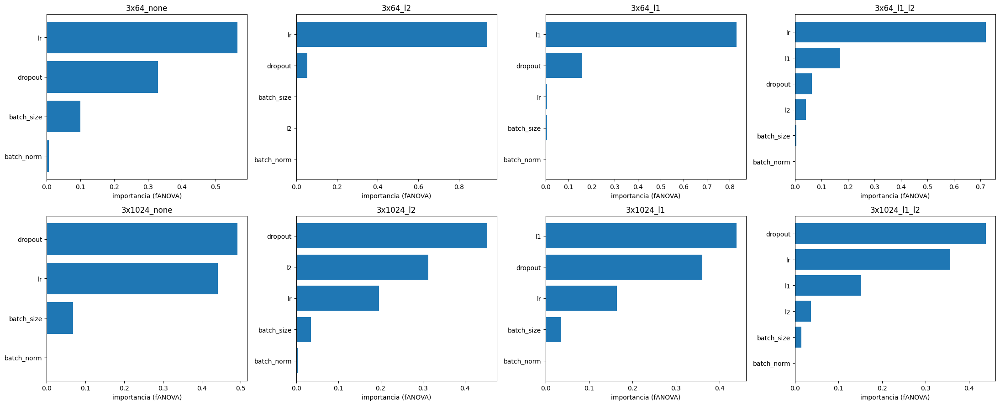

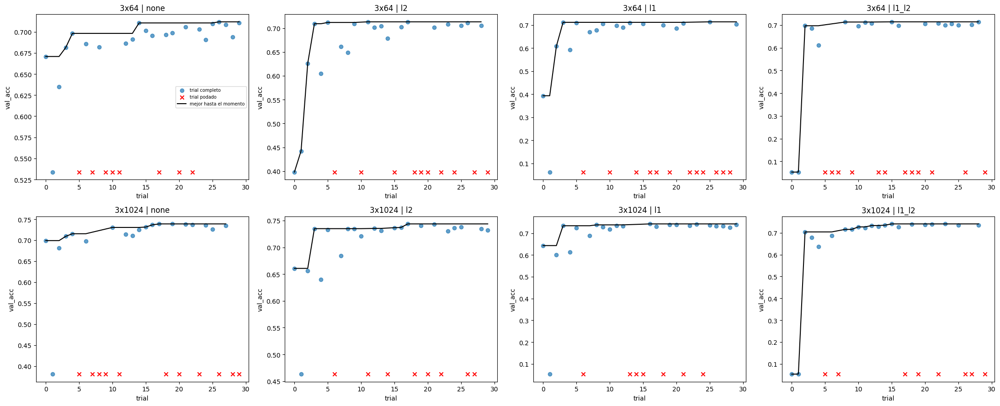

In [24]:
def border_report(df, top_k=10, margin=0.1):
    rows = []
    for (arch, reg), g in df[df["state"] == "COMPLETE"].groupby(["arquitectura", "regularizacion"]):
        sub = g.nlargest(top_k, "value")
        for name, (low, high, log) in REG_BOUNDS.items():
            col = f"params_{name}"
            if col not in sub.columns or sub[col].isna().all():
                continue
            v = sub[col].dropna().to_numpy(dtype=float)
            if log:
                z = (np.log(v) - np.log(low)) / (np.log(high) - np.log(low))
            else:
                z = (v - low) / (high - low)
            rows.append({"arquitectura": arch, "regularización": reg, "hiperparámetro": name,
                         "mín. observado": v.min(), "máx. observado": v.max(),
                         "cerca del límite inferior": int((z <= margin).sum()),
                         "cerca del límite superior": int((z >= 1 - margin).sum()), "de": len(v)})
        v = sub["params_batch_size"].to_numpy()
        rows.append({"arquitectura": arch, "regularización": reg, "hiperparámetro": "batch_size",
                     "mín. observado": v.min(), "máx. observado": v.max(),
                     "cerca del límite inferior": int((v == min(BATCH_SIZES)).sum()),
                     "cerca del límite superior": int((v == max(BATCH_SIZES)).sum()), "de": len(v)})
    return pd.DataFrame(rows).set_index(["arquitectura", "regularización", "hiperparámetro"])


border_tbl = border_report(df_reg)
border_tbl.to_csv(f"{RESULTS_DIR}/chequeo_de_bordes_reg.csv")
display(border_tbl.round(6))

fig, axes = plt.subplots(len(ARCHS_SEARCH), len(REG_TYPES), figsize=(5.5 * len(REG_TYPES), 4.5 * len(ARCHS_SEARCH)), squeeze=False)
importances = {}
for r, arch in enumerate(ARCHS_SEARCH):
    for c, reg in enumerate(REG_TYPES):
        key = f"{arch}_{reg}"
        ax = axes[r, c]
        try:
            imp = pd.Series(optuna.importance.get_param_importances(studies_reg[key])).sort_values()
            importances[key] = imp
            ax.barh(imp.index, imp.values)
            ax.set(title=key, xlabel="importancia (fANOVA)")
        except Exception as e:
            ax.set_title(f"{key}: no disponible")
            print(f"No se pudo calcular la importancia para {key}:", e)
plt.tight_layout()
plt.show()
if importances:
    pd.DataFrame(importances).to_csv(f"{RESULTS_DIR}/importancia_reg.csv")

fig, axes = plt.subplots(len(ARCHS_SEARCH), len(REG_TYPES), figsize=(5.5 * len(REG_TYPES), 4.5 * len(ARCHS_SEARCH)), squeeze=False)
for r, arch in enumerate(ARCHS_SEARCH):
    for c, reg in enumerate(REG_TYPES):
        g = df_reg[(df_reg["arquitectura"] == arch) & (df_reg["regularizacion"] == reg)].sort_values("number")
        g_done = g[g["state"] == "COMPLETE"]
        g_prun = g[g["state"] == "PRUNED"]
        ax = axes[r, c]
        ax.scatter(g_done["number"], g_done["value"], alpha=0.7, label="trial completo")
        if len(g_prun):
            ax.scatter(g_prun["number"], [g_done["value"].min()] * len(g_prun), marker="x", color="red", label="trial podado")
        ax.plot(g_done["number"], g_done["value"].cummax(), color="k", label="mejor hasta el momento")
        ax.set(title=f"{arch} | {reg}", xlabel="trial", ylabel="val_acc")
        if r == 0 and c == 0:
            ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 9. Evaluación final

Para cada arquitectura se comparan tres condiciones, con las mismas semillas, el mismo hardware y el mismo protocolo (entrenar con todo el train y evaluar en el test real, que no se usó antes):

1. **Sobreajustada**: la configuración original sin regularización, con el número de épocas con que se definió el sobreajuste.
2. **Solo early stopping**: la misma red sin regularización, entrenada hasta la mejor época de validación de la partición de búsqueda (semilla 42, con `PATIENCE`). Aísla cuánto del beneficio se debe simplemente a detener antes.
3. **Regularizada**: el mejor trial de los estudios de esa arquitectura (cualquier tipo de regularización), entrenado hasta su mejor época de validación.

Ninguna cantidad de épocas se elige mirando el test; durante el entrenamiento se registra la accuracy de test por época solo para monitoreo (aparece como `val` en los historiales). Se reporta media ± desvío entre las `FINAL_SEEDS`, la diferencia pareada por semilla frente a las dos condiciones sin regularización (con error estándar y test t) y también peso absoluto medio, porcentaje de pesos casi nulos, ruido de las curvas y tiempos.

Las semillas varían inicialización, dropout y orden de los lotes, pero no la partición ni el conjunto de test, por lo que el test t no incorpora el error de muestreo del conjunto de test.

In [25]:
best = best_by_arch(studies_reg)
for arch, b in best.items():
    print(f"{arch}: mejor estudio = {b['estudio']} | val_acc = {b['trial'].value:.4f} | cfg = "
          f"{ {k: v for k, v in b['cfg'].items() if k != 'hidden_units'} }")

conditions = {}
for arch_name in ARCHS_SEARCH:
    base_cfg = variant(hidden_units=ARCHS[arch_name])
    h_es = run_one(base_cfg, SEED, EPOCHS_SEARCH, f"es_{arch_name}", patience=PATIENCE)
    conditions[arch_name] = {
        "sobreajustada": (base_cfg, overfit_config["epochs"]),
        "solo early stopping": (base_cfg, h_es["best_epoch"]),
        "regularizada": (best[arch_name]["cfg"], best[arch_name]["trial"].user_attrs["best_epoch"]),
    }
    print(f"{arch_name}: épocas -> " + ", ".join(f"{c}: {e}" for c, (_, e) in conditions[arch_name].items()))

mlflow.end_run()
final_runs = {}
for arch_name, conds in conditions.items():
    for cond, (cfg, epochs) in conds.items():
        for i, seed in enumerate(FINAL_SEEDS):
            final_runs[(arch_name, cond, seed)] = run_one(cfg, seed, epochs, f"final_{arch_name}_{cond}",
                                                          data="full", store_sample=(i == 0))
        print(f"final | {arch_name} | {cond}: listo")

rows = []
for (arch, cond, seed), h in final_runs.items():
    test_acc = accuracy_score(h["labels"], h["preds"])
    rows.append({
        "arquitectura": arch, "condición": cond, "semilla": seed, "épocas": h["epochs_run"],
        "test_acc": test_acc, "test_macro_F1": f1_score(h["labels"], h["preds"], average="macro"),
        "train_acc final": h["final_train_acc"], "gap train - test": h["final_train_acc"] - test_acc,
        "tiempo (s)": h["train_time"], "s/época": float(np.mean(h["epoch_time"])),
        "mean |w| capa 1": h["w_abs_final"][0], "% pesos |w|≤1e-3": 100 * h["sparsity"],
        "ruido train_acc": h["noise_train_acc"], "ruido test_acc": h["noise_val_acc"],
    })
df_final = pd.DataFrame(rows)
df_final.to_csv(f"{RESULTS_DIR}/final_por_semilla.csv", index=False)

metric_cols = ["test_acc", "test_macro_F1", "train_acc final", "gap train - test", "tiempo (s)", "s/época",
               "mean |w| capa 1", "% pesos |w|≤1e-3", "ruido train_acc", "ruido test_acc"]
final_agg = df_final.groupby(["arquitectura", "condición"], sort=False)[metric_cols].agg(["mean", "std"]).round(4)
final_agg.to_csv(f"{RESULTS_DIR}/final_media_desvio.csv")
display(final_agg)

paired_rows = []
for arch in ARCHS_SEARCH:
    piv = df_final[df_final["arquitectura"] == arch].pivot(index="semilla", columns="condición", values="test_acc")
    for ref in ["sobreajustada", "solo early stopping"]:
        diff = piv["regularizada"] - piv[ref]
        se = diff.std(ddof=1) / np.sqrt(len(diff))
        t_stat, p_value = stats.ttest_rel(piv["regularizada"], piv[ref])
        paired_rows.append({"arquitectura": arch, "comparación": f"regularizada - {ref}",
                            "diferencia de test_acc": diff.mean(), "error estándar": se,
                            "t": t_stat, "p": p_value, "supera 2 errores estándar": bool(abs(diff.mean()) > 2 * se)})
df_paired = pd.DataFrame(paired_rows)
df_paired.to_csv(f"{RESULTS_DIR}/final_comparaciones_pareadas.csv", index=False)
display(df_paired.round(5))

3x64: mejor estudio = 3x64_l1_l2 | val_acc = 0.7141 | cfg = {'activation': 'relu', 'dropout': 0.2, 'batch_norm': True, 'l1': 3.23136186528775e-05, 'l2': 8.162038126994559e-06, 'layer_growth': 1.0, 'lr': 0.0006345044787086925, 'batch_size': 256}
3x1024: mejor estudio = 3x1024_l2 | val_acc = 0.7437 | cfg = {'activation': 'relu', 'dropout': 0.7, 'batch_norm': True, 'l1': 0.0, 'l2': 4.591209981103596e-06, 'layer_growth': 1.0, 'lr': 0.0011567161529345744, 'batch_size': 256}
3x64: épocas -> sobreajustada: 20, solo early stopping: 5, regularizada: 4
3x1024: épocas -> sobreajustada: 20, solo early stopping: 5, regularizada: 5
final | 3x64 | sobreajustada: listo
final | 3x64 | solo early stopping: listo
final | 3x64 | regularizada: listo
final | 3x1024 | sobreajustada: listo
final | 3x1024 | solo early stopping: listo
final | 3x1024 | regularizada: listo


test_acc         test_macro_F1          \
                                     mean     std          mean     std   
arquitectura condición                                                    
3x64         sobreajustada         0.5481  0.0100        0.5411  0.0108   
             solo early stopping   0.5652  0.0047        0.5614  0.0034   
             regularizada          0.6483  0.0028        0.6363  0.0054   
3x1024       sobreajustada         0.6099  0.0128        0.6051  0.0114   
             solo early stopping   0.6187  0.0098        0.6149  0.0087   
             regularizada          0.6721  0.0040        0.6660  0.0036   

                                 train_acc final         gap train - test  \
                                            mean     std             mean   
arquitectura condición                                                      
3x64         sobreajustada                0.9713  0.0006           0.4232   
             solo early stopping          0.9484  0.0037           0.3832   
             regularizada                 0.8586  0.0052           0.2102   
3x1024       sobreajustada                0.9642  0.0174           0.3544   
             solo early stopping          0.9702  0.0006           0.3515   
             regularizada                 0.8950  0.0046           0.2229   

                                         tiempo (s)         s/época          \
                                     std       mean     std    mean     std   
arquitectura condición                                                        
3x64         sobreajustada        0.0101     7.8677  0.1254  0.3934  0.0063   
             solo early stopping  0.0021     1.9631  0.1081  0.3926  0.0216   
             regularizada         0.0051     0.8299  0.0626  0.2075  0.0156   
3x1024       sobreajustada        0.0053    34.4500  0.1857  1.7225  0.0093   
             solo early stopping  0.0095     8.6667  0.0219  1.7333  0.0044   
             regularizada         0.0050     4.3328  0.0069  0.8666  0.0014   

                                 mean |w| capa 1         % pesos |w|≤1e-3  \
                                            mean     std             mean   
arquitectura condición                                                      
3x64         sobreajustada                0.0430  0.0006           1.5121   
             solo early stopping          0.0354  0.0009           1.8446   
             regularizada                 0.0036  0.0000          32.7273   
3x1024       sobreajustada                0.0181  0.0027           3.9513   
             solo early stopping          0.0147  0.0002           4.4521   
             regularizada                 0.0097  0.0000           6.0127   

                                         ruido train_acc          \
                                     std            mean     std   
arquitectura condición                                             
3x64         sobreajustada        0.1106          0.0019  0.0003   
             solo early stopping  0.1964             NaN     NaN   
             regularizada         0.1828             NaN     NaN   
3x1024       sobreajustada        0.3301          0.0016  0.0012   
             solo early stopping  0.0552             NaN     NaN   
             regularizada         0.0248             NaN     NaN   

                                 ruido test_acc          
                                           mean     std  
arquitectura condición                                   
3x64         sobreajustada               0.0021  0.0004  
             solo early stopping            NaN     NaN  
             regularizada                   NaN     NaN  
3x1024       sobreajustada               0.0035  0.0011  
             solo early stopping            NaN     NaN  
             regularizada                   NaN     NaN

,arquitectura,comparación,diferencia de test_acc,error estándar,t,p,supera 2 errores estándar
0,3x64,regularizada - sobreajustada,0.10021,0.00490,20.46859,0.00003,True
1,3x64,regularizada - solo early stopping,0.08314,0.00273,30.46345,0.00001,True
2,3x1024,regularizada - sobreajustada,0.06224,0.00602,10.34740,0.00049,True
3,3x1024,regularizada - solo early stopping,0.05340,0.00486,10.97809,0.00039,True


Las figuras siguientes muestran, para cada arquitectura y condición, la accuracy de entrenamiento y de test por época (media ± desvío entre semillas) y la distribución de los pesos de la primera capa de la semilla 42. Permiten ver dónde empieza la separación entre entrenamiento y test en cada condición y si la regularización modifica la escala de los pesos.

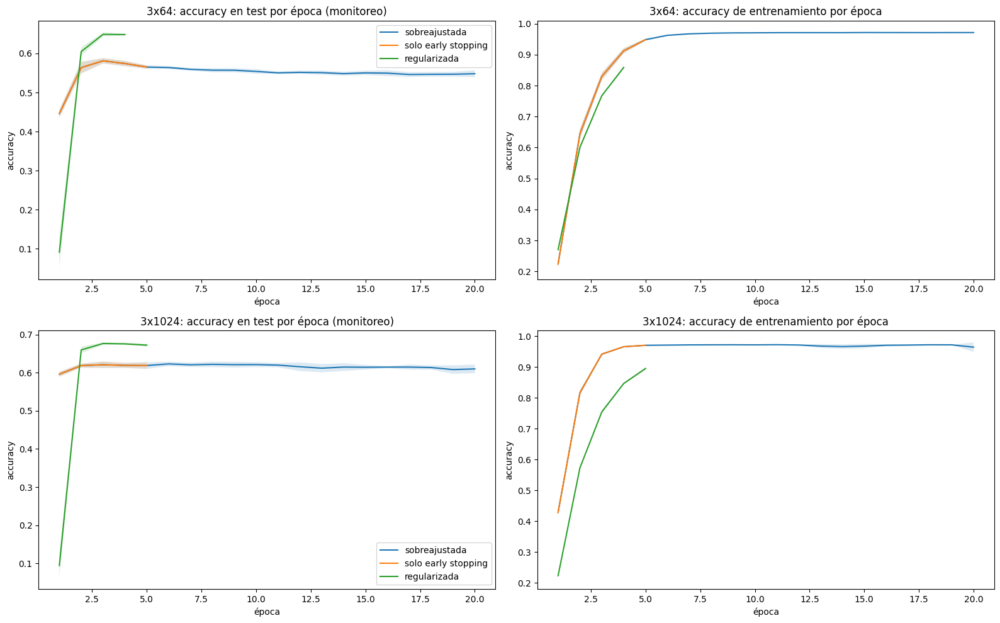

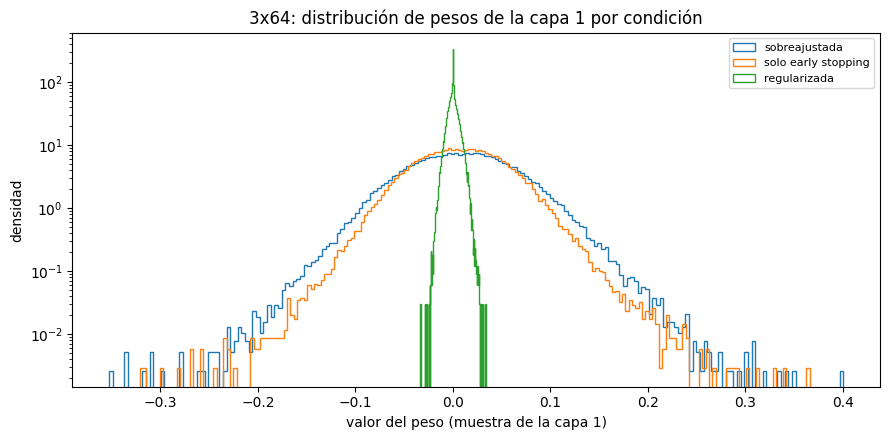

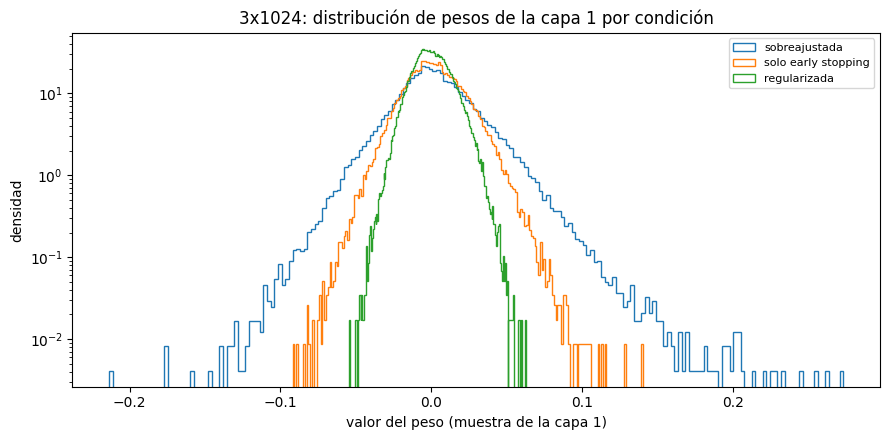

In [26]:
fig, axes = plt.subplots(len(ARCHS_SEARCH), 2, figsize=(16, 5 * len(ARCHS_SEARCH)), squeeze=False)
for r, arch in enumerate(ARCHS_SEARCH):
    for cond in conditions[arch]:
        hs = [final_runs[(arch, cond, s)] for s in FINAL_SEEDS]
        band(axes[r, 0], [h["val_acc"] for h in hs], cond)
        band(axes[r, 1], [h["train_acc"] for h in hs], cond)
    axes[r, 0].set(title=f"{arch}: accuracy en test por época (monitoreo)", xlabel="época", ylabel="accuracy")
    axes[r, 1].set(title=f"{arch}: accuracy de entrenamiento por época", xlabel="época", ylabel="accuracy")
    axes[r, 0].legend()
plt.tight_layout()
plt.show()

for arch in ARCHS_SEARCH:
    plot_weight_hist({cond: final_runs[(arch, cond, FINAL_SEEDS[0])]["w_sample"] for cond in conditions[arch]},
                     f"{arch}: distribución de pesos de la capa 1 por condición")

## 10. Conclusiones

Todos los tiempos se midieron con `time.perf_counter()` en una GPU NVIDIA T4. La partición de validación de la búsqueda tiene 2.263 documentos, por lo que una accuracy de 0.70–0.75 tiene un error de muestreo de aproximadamente ±0.9 puntos porcentuales. Los experimentos controlados (sección 6) usan la red de 3 capas × 64 neuronas con 3 semillas; la búsqueda (sección 7) y la evaluación final (sección 9) incluyen también la red de 3 × 1024. Los desvíos son entre semillas.

### 10.1 Resultado final (sección 9)

| Arquitectura | Condición | Épocas | Test acc | Macro-F1 | Train acc | Gap train–test | Tiempo (s) | s/época | Peso abs. medio capa 1 | % pesos casi nulos |
|---|---|---|---|---|---|---|---|---|---|---|
| 3×64 | sobreajustada | 20 | 0.5481 ± 0.0100 | 0.5411 ± 0.0108 | 0.9713 | 0.4232 | 7.87 | 0.393 | 0.0430 | 1.5 |
| 3×64 | solo early stopping | 5 | 0.5652 ± 0.0047 | 0.5614 ± 0.0034 | 0.9484 | 0.3832 | 1.96 | 0.393 | 0.0354 | 1.8 |
| 3×64 | **regularizada** | 4 | **0.6483 ± 0.0028** | **0.6363 ± 0.0054** | 0.8586 | **0.2102** | 0.83 | 0.208 | 0.0036 | 32.7 |
| 3×1024 | sobreajustada | 20 | 0.6099 ± 0.0128 | 0.6051 ± 0.0114 | 0.9642 | 0.3544 | 34.45 | 1.723 | 0.0181 | 4.0 |
| 3×1024 | solo early stopping | 5 | 0.6187 ± 0.0098 | 0.6149 ± 0.0087 | 0.9702 | 0.3515 | 8.67 | 1.733 | 0.0147 | 4.5 |
| 3×1024 | **regularizada** | 5 | **0.6721 ± 0.0040** | **0.6660 ± 0.0036** | 0.8950 | **0.2229** | 4.33 | 0.867 | 0.0097 | 6.0 |

(5 semillas; "casi nulos" = |w| ≤ 10⁻³.)

| Arquitectura | Comparación pareada | Diferencia de test acc | Error estándar | t | p |
|---|---|---|---|---|---|
| 3×64 | regularizada − sobreajustada | +0.1002 | 0.0049 | 20.5 | 3·10⁻⁵ |
| 3×64 | regularizada − solo early stopping | +0.0831 | 0.0027 | 30.5 | 1·10⁻⁵ |
| 3×1024 | regularizada − sobreajustada | +0.0622 | 0.0060 | 10.3 | 4.9·10⁻⁴ |
| 3×1024 | regularizada − solo early stopping | +0.0534 | 0.0049 | 11.0 | 3.9·10⁻⁴ |

- **La regularización mejora de forma consistente**: las cuatro diferencias superan 8 errores estándar y las 5 semillas van en el mismo sentido. El test t no incorpora el error de muestreo del conjunto de test, que no cambia entre semillas.
- **Detenerse antes no explica el beneficio.** Solo early stopping suma 1.7 puntos en 3×64 (un desvío entre semillas de 0.5 a 1.0) y 0.9 puntos en 3×1024, dentro del desvío entre semillas (0.010–0.013). Sí reduce el tiempo de entrenamiento unas 4 veces. No se hizo una prueba pareada de esta comparación.
- **El sobreajuste se reduce pero no desaparece**: el gap entre entrenamiento y test baja de 0.42 a 0.21 (3×64) y de 0.35 a 0.22 (3×1024).
- **Validación vs test.** Las accuracy de validación de los mejores trials (0.7141 y 0.7437) caen a 0.6483 y 0.6721 en test: unos 7 puntos. Es compatible con el sesgo optimista de elegir el mejor de 239 trials y con que el test oficial de 20 Newsgroups sea posterior en el tiempo; ambos efectos no se separaron.
- **Referencia.** En el notebook `02_MLP_20Newsgroups`, el MLP de una capa de 128 unidades alcanzó 0.7033 ± 0.0013 y la regresión softmax 0.6837 ± 0.0005 sobre el mismo test. Las redes de tres capas regularizadas quedan por debajo de ambas, de modo que la regularización reduce el sobreajuste de la red sobredimensionada pero no la lleva a superar al modelo de una capa.

### 10.2 Fenómenos observados y fundamento

**Tamaño de los pesos y sobreajuste (6.1).** El valor absoluto medio de los pesos de la primera capa es 0.0461 tras 40 épocas y 0.0558 con la misma configuración tras 60 (+21 %), mientras la `val_acc` final baja de 0.6184 a 0.6092. Con la inicialización por defecto de PyTorch el valor inicial sería de unos 0.0035 (estimado a partir de la regla de inicialización, no medido), de modo que los pesos crecieron cerca de 13 veces. Coincide con lo esperado: sobreajustar exige curvas cerradas, y eso exige pesos grandes.

**L2 (6.2).**
- Aumentar λ₂ contrae los pesos de forma continua: 0.0461 (sin regularizar), 0.0227 (λ = 10⁻⁵), 0.0107 (3·10⁻⁴) y 0.00001 (3·10⁻³). Con λ = 3·10⁻³ todos los pesos quedan en cero y la accuracy es 0.053, nivel de azar (underfitting total). Con λ = 10⁻³ una de las tres semillas colapsa (`train_acc` 0.63 ± 0.41).
- Entre 10⁻⁶ y 10⁻⁴ la accuracy de entrenamiento no baja (0.971–0.972) y la `val_acc` disminuye de forma monótona (mejor `val_acc` 0.6254 a 0.5776, frente a 0.6372 sin regularizar). El gap pasa de 0.354 a 0.403–0.413. La regularización no redujo la memorización del entrenamiento ni mejoró la generalización.
- La relación entre la pérdida de validación final y su mínimo sí baja con λ ≥ 10⁻⁴ (de 2.08 a 1.73 y 1.45), pero a costa de menor accuracy y de un entrenamiento mucho más lento (mejor época 37.7 con λ = 3·10⁻⁴, contra 3.7).
- No coincide con la expectativa de que L2 mejore en un rango amplio de λ.
-  Una razón por la cual puede haber fallado en mejorar la capacidad de generalización de loss modelos es que, con Adam, el paso de cada peso se normaliza por la magnitud de su gradiente, de modo que los pesos de términos raros (cuyo gradiente de datos es casi nulo) son arrastrados hacia cero por la penalidad sin importar cuán chico sea λ. Una penalidad L2 sumada a la loss se comporta distinto con un optimizador adaptativo que con descenso por gradiente simple.

**L1 y pruning (6.3).**
- La fracción de pesos casi nulos sube de 35.5 % (λ₁ = 10⁻⁷) a 73.6 % (10⁻⁵), y la mejor `val_acc` cae de 0.6231 a 0.5628. Con λ₁ = 10⁻⁴ el modelo colapsa.
- A una esparsidad comparable (≈ 34–36 % de pesos casi nulos), L1 conserva 0.6231 de `val_acc` frente a 0.5525 de L2 (λ = 3·10⁻⁴): L1 pierde menos precisión por cada peso eliminado, coherente con su rol de selector de parámetros.
- Pruning por magnitud sin reentrenar: ninguna de las tres redes (sin regularizar, L2 y L1) cambia su `val_acc` (variaciones ≤ 0.001) al anular hasta el 13 %, 40 % y 47 % de los pesos respectivamente. La grilla de umbrales no llegó a podar el modelo sin regularizar más allá del 13 %, por lo que **la comparación a igual esparsidad no es concluyente**.
- Con Adam, el paso de actualización es del orden del `lr` (10⁻³), igual al umbral usado para contar pesos "casi nulos"; los pesos que oscilan alrededor de cero cuentan como nulos tanto en L1 como en L2, lo que limita distinguir ambas por este indicador.

**L1 + L2 (6.4).** Ninguna de las 8 combinaciones supera a la referencia (0.6209–0.6284 contra 0.6372) y las diferencias entre combinaciones (≤ 0.8 puntos) están dentro del desvío entre semillas (0.009–0.014). No hay sinergia observable entre los dos términos.

**λ por capa (6.5).** Penalizar ×3 más a cada capa sucesiva da lo mismo que el λ uniforme (0.6251 contra 0.6263). Con ×10 la `val_acc` baja a 0.5986, el peso medio de la capa de salida cae de 0.116 a 0.051 y la relación entre pérdida final y mínima de validación baja de 2.33 a 1.65. Castigar más a las capas cercanas a la salida no resultó beneficioso en este problema.

**Dropout (6.6; `lr` base 10⁻³).**

| Tasa | `val_acc` | Gap | Ruido de `train_acc` | Época de conv. | Tiempo hasta converger (s) |
|---|---|---|---|---|---|
| 0.0 | 0.6372 | 0.363 | 0.0014 | 3.7 | 1.16 |
| 0.1 | 0.6494 | 0.332 | 0.0017 | 10.7 | 3.66 |
| 0.3 | 0.6712 | 0.298 | 0.0023 | 19.0 | 6.62 |
| 0.5 | **0.6836** | 0.231 | 0.0028 | 40.0 | 14.01 |
| 0.7 | 0.5921 | 0.060 | 0.0038 | 47.0 | 16.52 |

- **Ruido.** El ruido de la `train_acc` crece con la tasa (2.7 veces entre 0 y 0.7). El de `val_acc` no crece hasta 0.7 (0.0030 sin dropout, 0.0023 entre 0.2 y 0.5): la red completa de validación es estable y el ruido proviene del entrenamiento con neuronas apagadas.
- **Épocas y costo.** Se necesitan muchas más épocas (de 3.7 a 40–47 con tasas ≥ 0.5); con tasas ≥ 0.3, la mejor época (43–52 de 60) está cerca del límite del experimento, así que no están completamente convergidos. El costo por época sube un 11–17 %, y el costo total viene sobre todo de las épocas extra.
- **Learning rate.** Con `lr` ×10, el dropout mejora entre 2.1 y 2.4 puntos para tasas ≤ 0.3 (el mejor, 0.6955 con tasa 0.3) y empeora para tasas ≥ 0.5 (0.6256 con 0.5; 0.3182 con 0.7), en línea con la recomendación de subir el `lr` con dropout, pero solo hasta cierto nivel de apagado.
- **Capacidad.** Con 64 unidades, una tasa de 0.7 produce underfitting (`train_acc` 0.64). Con 1024 unidades, en cambio, los mejores trials de la búsqueda usan tasas de 0.5 a 0.7 (sección 10.4), coherente con la recomendación de usar redes sobredimensionadas.
- **Sobreajuste residual.** Incluso el mejor dropout deja un gap de 0.249 (`train_acc` 0.935 contra `val_acc` 0.686).

**BatchNorm (6.7).**
- Con `lr` = 10⁻³, BatchNorm sube la `val_acc` de 0.6372 a 0.7085 (+7.1 puntos), baja la época de convergencia de 3.7 a 2.0 y el gap de 0.354 a 0.288. Cada época cuesta un 22 % más (0.377 contra 0.308 s).
- **Tolerancia al `lr`.** Con `lr` = 0.1 la red sin BatchNorm colapsa (0.2887 ± 0.0566) y con BatchNorm llega a 0.6518 ± 0.0006. Pero con BatchNorm la `val_acc` baja al subir el `lr` (0.7085, 0.6798, 0.6518): la técnica tolera `lr` altos, aunque aquí no se beneficia de ellos.
- **Ruido.** Con `lr` = 10⁻³ el ruido de `train_acc` sube de 0.0018 a 0.0038 (efecto del ruido de estimar μ y σ por lote), y con `lr` = 0.1 baja de 0.0117 a 0.0027.
- **Pesos.** El peso medio de la primera capa es menor con BatchNorm a `lr` = 10⁻³ (0.0283 contra 0.0461) y mucho mayor con `lr` = 0.1 (3.01). Como cada capa lineal seguida de BatchNorm es invariante a la escala de sus pesos, esa medida no es comparable entre redes con y sin BatchNorm.

**Dropout + BatchNorm (6.7 y 8).** La recomendación teórica es no combinarlos. En el experimento controlado (`lr` = 10⁻²), dropout 0.3 + BatchNorm alcanza 0.7038 ± 0.0013, contra 0.6798 ± 0.0046 de BatchNorm solo y 0.6955 ± 0.0044 de dropout solo. En la búsqueda, los trials con ambos promedian 0.7324 (3×1024, n = 62) y 0.7032 (3×64, n = 48), contra 0.7119 (n = 5) y 0.6947 (n = 12) de BatchNorm solo. No se observó el perjuicio esperado en esta configuración (dropout después de la activación y BatchNorm antes de ella), pero la ventaja sobre BatchNorm solo (0.8 a 2 puntos) se apoya en pocos trials de BatchNorm solo.

**Learning rate y ruido.** Sin BatchNorm, el ruido de `val_acc` crece con el `lr` (0.0031, 0.0050 y 0.0125 para 10⁻³, 10⁻² y 10⁻¹) y a `lr` = 0.1 la `val_acc` colapsa a 0.2887. En la búsqueda, el mejor cuartil de `lr` para 3×1024 es 7.3·10⁻⁴ a 4.3·10⁻³ (media 0.7231 ± 0.0177), mientras que por encima el desvío sube a 0.139. En 3×64, el cuartil de `lr` más bajo (≤ 3.4·10⁻⁴) rinde peor (0.453) por entrenar muy lento.

**Early stopping.** Es coherente con lo esperado: reduce el tiempo de entrenamiento unas 4 veces y limita el crecimiento de los pesos (0.0430 a 0.0354 en 3×64; 0.0181 a 0.0147 en 3×1024), aunque su aporte de accuracy es chico (sección 10.1).

### 10.3 Tiempos de entrenamiento

| Técnica (3×64, `batch_size` 64) | Segundos por época | Sobre la referencia (0.31 s) | Tiempo hasta converger |
|---|---|---|---|
| L2 | 0.411–0.418 | +32–34 % | 1.7–2.3 s (15.1 s con λ = 3·10⁻⁴) |
| L1 | 0.399–0.413 | +28–32 % | 1.7–2.3 s (14.6 s con λ = 3·10⁻⁵) |
| L1 + L2 | 0.494–0.512 | +58–64 % | 1.7–2.5 s |
| Dropout | 0.341–0.361 | +11–17 % | 3.7–16.5 s |
| BatchNorm | 0.377 | +22 % | 0.82 s |

- La referencia se midió en tres corridas independientes con valores 0.312, 0.306 y 0.308 s/época.
- La penalidad L1/L2 es la técnica más cara por época (se evalúa sobre todos los pesos en cada paso) y no mejora el resultado. El dropout es barato por época pero caro en tiempo total, porque necesita muchas más épocas. BatchNorm es la que más reduce el tiempo hasta converger.
- **Pruning.** De los 239 trials, 76 fueron podados (32 %). Se estima que se ahorraron 305.5 s de 467.5 s (65 %), cerca del 20 % de los 1.542 s de búsqueda. Por estudio, el ahorro estimado va de 55 % a 78 %. La búsqueda de la red 3×1024 tardó 1.033 s y la de 3×64, 509 s.

### 10.4 Búsqueda (sección 8)

| Estudio | Mejor `val_acc` | Mejores hiperparámetros |
|---|---|---|
| 3×64, sin L1/L2 | 0.7119 | dropout 0.3, BatchNorm, `lr` 8.8·10⁻⁴, `batch_size` 128 |
| 3×64, L2 | 0.7132 | λ₂ = 3.4·10⁻³ |
| 3×64, L1 | 0.7137 | λ₁ ≈ 0 |
| 3×64, L1 + L2 | **0.7141** | λ₁ = 3.2·10⁻⁵, λ₂ = 8·10⁻⁶, dropout 0.2, `lr` 6.4·10⁻⁴, `batch_size` 256 |
| 3×1024, sin L1/L2 | 0.7388 | dropout 0.6, `lr` 3.0·10⁻³, `batch_size` 512 |
| 3×1024, L2 | **0.7437** | λ₂ = 4.6·10⁻⁶, dropout 0.7, `lr` 1.2·10⁻³, `batch_size` 256 |
| 3×1024, L1 | 0.7424 | λ₁ ≈ 0, dropout 0.7 |
| 3×1024, L1 + L2 | 0.7411 | dropout 0.5, `lr` 2.2·10⁻⁴ |

- **El tipo de regularización L1/L2 no se distingue.** Las diferencias entre estudios de una misma arquitectura (0.2 puntos en 3×64, 0.5 en 3×1024) están dentro del error de muestreo de la validación (±0.9). En los diez mejores trials de cada arquitectura (0.7110–0.7141 y 0.7388–0.7437) se mezclan todos los tipos y **los 20 usan BatchNorm**. Los λ de los mejores trials son muy chicos (por ejemplo, λ₂ = 4.6·10⁻⁶ en el mejor de 3×1024).
- **L1/L2 empeora el promedio sin mejorar el máximo.** Por ejemplo, en 3×64 la `val_acc` media de los trials completos es 0.6864 sin L1/L2 (n = 22) y 0.6629, 0.6356 y 0.6262 con L2, L1 y L1 + L2: el hiperparámetro adicional aporta más formas de fallar.
- **Efecto sobre los pesos.** En 3×64, el peso medio de la primera capa pasa de 0.0711 sin L1/L2 a 0.0199, 0.0217 y 0.0109 con L2, L1 y L1 + L2, y los pesos casi nulos de 2.4 % a 14.0 %, 33.1 % y 38.0 %. En 3×1024 pasan de 0.0571 a 0.0082, 0.0129 y 0.0035, y de 3.0 % a 21.6 %, 29.3 % y 53.7 %. Es el efecto más claro de L1/L2: dispersan los pesos, y más L1 que L2, pero sin mejorar el rendimiento.
- **BatchNorm vuelve robusta la búsqueda.** Los trials completos con BatchNorm promedian 0.7309 ± 0.0112 (3×1024) y 0.7015 ± 0.0114 (3×64), contra 0.5335 ± 0.2362 y 0.4989 ± 0.2230 sin ella: el desvío entre trials baja unas 20 veces. TPE concentró el 75 % de los trials en BatchNorm, así que la rama sin BatchNorm está menos explorada.
- **Redes anchas toleran más dropout.** Los mejores trials de 3×1024 usan tasas de 0.5 a 0.7, y los de 3×64, de 0.2 a 0.4.
- **Importancia (fANOVA).** En 3×64, el `lr` domina en los estudios sin L1/L2 (0.565), con L2 (0.939) y con L1 + L2 (0.721), y λ₁ en el de L1 (0.829). En 3×1024 domina el dropout (0.36–0.49), con `lr` o λ₁ en segundo lugar. La importancia de λ₂ es 0.002 en 3×64 con L2 y 0.313 en 3×1024. La importancia de `batch_norm` es casi nula (≤ 0.006) pese a la gran diferencia de medias: no se pudo conciliar, y es probable que se deba a la interacción con el `lr` y al desbalance del muestreo. La importancia es correlacional.
- **Bordes del espacio (`border_tbl`).** En tres de los cuatro estudios de 3×1024, 4 de los 10 mejores trials usan el dropout máximo probado (0.7), por lo que el óptimo puede estar en o por encima de ese valor. En 3×64 con L1 y con L2, 6 y 8 de los 10 mejores usan `batch_size` cercano al mínimo (64). En L1 + L2 de 3×1024, 4 de 10 tienen λ₂ cerca del límite superior y 3 de 10, `lr` cerca del inferior. Para esos hiperparámetros no puede afirmarse un óptimo.
- **Muestreo.** El `batch_size` 256 concentró 55 de 119 trials de 3×1024 y 39 de 120 de 3×64.
- Un trial de 3×1024 con L1 + L2 no quedó registrado como terminado (29 de 30), por lo que la búsqueda total tiene 239 trials.

### 10.5 Limitaciones
1. Los experimentos controlados se hicieron solo con la red de 3×64 y con 40 o 60 épocas fijas; con dropout ≥ 0.3 no llegaron a converger completamente.
2. L1 y L2 se sumaron a la loss con Adam. La explicación propuesta para su falta de efecto (interacción con el paso adaptativo) no fue verificada; no se probó con otro optimizador ni con decaimiento desacoplado.
3. La poda por magnitud no cubrió umbrales que permitan comparar los tres modelos a igual esparsidad, y el umbral de "casi nulo" (10⁻³) es del orden del `lr`.
4. Una única partición de validación, fija; el test t no incorpora el error de muestreo del test; el efecto de seleccionar entre 239 trials no se cuantificó.
5. En las condiciones "solo early stopping" y "regularizada" las curvas tienen 4–5 épocas, demasiado pocas para medir su ruido.
6. La búsqueda fijó el optimizador (Adam) y la activación; BatchNorm y dropout se evaluaron en una posición fija dentro de cada capa.
7. Todos los tiempos corresponden a una única GPU T4.

## 11. Exportación de artefactos

Se guardan las tablas de `results_reg/`, los logs de `runs_reg/`, la base de MLflow (`mlflow_reg.db`) y los artefactos de `mlruns/` en `artefactos_regularizacion.zip`. En Google Colab, además, se descarga el archivo.

In [27]:
mlflow.end_run()
ZIP_NAME = "artefactos_regularizacion.zip"
with zipfile.ZipFile(ZIP_NAME, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in [TB_DIR, RESULTS_DIR, "mlruns"]:
        for root, _, files in os.walk(folder):
            for name in files:
                z.write(os.path.join(root, name))
    if os.path.exists("mlflow_reg.db"):
        z.write("mlflow_reg.db")
print("Archivo generado:", ZIP_NAME, f"({os.path.getsize(ZIP_NAME) / 1e6:.1f} MB)")

try:
    from google.colab import files
    files.download(ZIP_NAME)
except ImportError:
    pass

Archivo generado: artefactos_regularizacion.zip (5.5 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Nota sobre el uso de IA
Se utilizaron modelos de inteligencia artificial para mejoras algun aspectos del trabajo, incluyendo:


*   optimización del código con el fin de reducir las redundancias y evitar imports repetidos,
*   resolución bugs existentes,
*   implementación herramientas avanzadas de estadística (como el fANOVA),
*   implementación herramientas de visualización (diagramas de caja y bigote, graficos de dispersión, graficos con bandas de error, graficos de barra, histogramas, entre otros),
*  mejoramiento de la redacción,
*   y cálculo de división óptima de las celdas y las secciones para mejorar la lectura del notebook y evitar problemas ante desconexiones de la GPU en el entorno de Google Collab.


